# España en cifras · XV Legislatura
### Análisis exploratorio del desempeño socioeconómico con datos oficiales del INE

> **Objetivo.** Evaluar con datos —no con opiniones— cómo han evolucionado el empleo, los precios, los salarios, la vivienda, el bienestar, la igualdad de género, la demografía y la justicia penal desde la investidura del Gobierno el **16 de noviembre de 2023**, de cara a las próximas elecciones generales.

**Fuente única:** Instituto Nacional de Estadística (API JSON Tempus3). Todas las cifras se descargan en vivo y son reproducibles.

| | |
|---|---|
| **Periodo analizado** | 2013 → último dato publicado |
| **Referencia** | Inicio de la XV Legislatura (T4 2023 / nov 2023) |
| **Comparador** | XIV Legislatura (enero 2020 → noviembre 2023) |
| **Series** | ~770 series INE de 40+ tablas |

---

### Índice
1. [Preparación y obtención de datos](#1)
2. [Calidad y cobertura del dataset](#2)
3. [Scorecard de la legislatura](#3)
4. [Mercado laboral](#4)
5. [Precios e inflación](#5)
6. [Salarios y poder adquisitivo](#6)
7. [Brecha salarial de género](#7)
8. [Crecimiento y actividad](#8)
9. [Vivienda](#9)
10. [Bienestar y desigualdad](#10)
11. [Demografía](#11)
12. [Justicia penal y nacionalidad](#12)
13. [Territorio: las 17 comunidades](#13)
14. [Relaciones macro y comparativa entre legislaturas](#14)
15. [Conclusiones y limitaciones](#15)

> **Nota de neutralidad.** El análisis mide *resultados*, no atribuye causalidad a políticas concretas. Muchos indicadores dependen del ciclo internacional (energía, tipos del BCE, turismo) y de decisiones de otras administraciones (CCAA, ayuntamientos).

<a id="1"></a>
## 1 · Preparación y obtención de datos

El proyecto se organiza en tres capas:

1. **`src/ine_client.py`** — cliente de la API Tempus3 con reintentos (algunas tablas responden *«petición en proceso»* la primera vez).
2. **`src/catalog.py`** — catálogo declarativo: qué serie se busca, en qué tabla, con qué expresión regular sobre el nombre oficial y en qué dirección es «mejor».
3. **`src/pipeline.py`** — descarga, normaliza a formato *tidy* (`key, dim, fecha, valor`) y guarda en `data/processed/`.

`src/analytics.py` contiene **toda** la lógica analítica; el notebook y el dashboard la reutilizan, así que ambos muestran exactamente las mismas cifras.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from src import analytics as A
from src import plotting as P
from src.catalog import BLOCKS, LEGISLATURES, SERIES
from src.pipeline import build, PROCESSED_DIR

P.setup()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
C = P.PALETTE

La descarga completa tarda ~1-2 minutos la primera vez; después se usa una caché local de 24 h (`data/raw/`). Para forzar datos frescos: `python -m src.pipeline --refresh`.

In [2]:
if not (PROCESSED_DIR / "series_long.csv").exists():
    build(verbose=False)

long_df = A.load_long()
catalog = A.load_catalog()
print(f"{len(long_df):,} observaciones · {long_df.groupby(['key','dim']).ngroups} series · {catalog['table'].nunique()} tablas INE")
print(f"Rango temporal: {long_df.fecha.min():%Y-%m} → {long_df.fecha.max():%Y-%m}")
long_df.sample(6, random_state=1)

22,328 observaciones · 769 series · 37 tablas INE
Rango temporal: 2009-01 → 2026-10


,key,dim,fecha,anyo,periodo,valor
275,arope_ccaa,Andalucía,2016-01-01,2016,A,43.10
11718,ocupados_sector,Total CNAE,2025-07-01,2025,T3,"22,776.70"
15333,pob_hist_sexo_edad_espanola,De 60 a 64 años. Mujeres,2022-07-01,2022,1 de julio de,"1,493,714.00"
5343,ipc_ccaa,Ceuta,2018-08-01,2018,M08,1.40
19185,salario_actividad_mujeres,"Actividades profesionales, científicas y técnicas",2010-01-01,2010,A,"21,309.65"
20173,salario_ccaa_mujeres,Galicia,2020-01-01,2020,A,"20,446.53"


<a id="2"></a>
## 2 · Calidad y cobertura del dataset

Antes de interpretar nada conviene saber **qué tenemos, desde cuándo y con qué retraso**. Las estadísticas del INE tienen calendarios muy distintos:

- **Mensuales** (IPC, turismo, hipotecas) llegan con 2-6 semanas de retraso.
- **Trimestrales** (EPA, PIB, IPV) con 1-3 meses.
- **Anuales** (ECV, salarios EAES, condenados) con 1-2 años: la ECV 2025 refleja rentas de 2024, y la EAES más reciente es de 2024.

Esto significa que **parte del balance de la legislatura todavía no es observable** en los indicadores estructurales.

In [3]:
cov = catalog.copy()
cov["first"] = pd.to_datetime(cov["first"]); cov["last"] = pd.to_datetime(cov["last"])
cov["retraso_meses"] = ((pd.Timestamp.today() - cov["last"]).dt.days / 30.4).round(1)
cov["bloque"] = cov["block"].map(BLOCKS)
resumen = cov.groupby("bloque").agg(indicadores=("key", "count"), series=("n_series", "sum"),
                                   observaciones=("n_obs", "sum"), retraso_medio_meses=("retraso_meses", "mean"))
display(resumen.sort_values("observaciones", ascending=False))
print("Series sin coincidencias:", cov.loc[cov.n_series == 0, "key"].tolist() or "ninguna")

,indicadores,series,observaciones,retraso_medio_meses
bloque,,,,
Precios,8,40,5967,1.11
Demografía,13,243,5416,15.42
Mercado laboral,15,72,2540,10.17
Justicia penal y nacionalidad,9,185,2397,21.90
Brecha de género,13,121,1835,34.00
Vivienda,10,46,1809,14.30
Crecimiento y actividad,8,13,1504,3.38
Salarios y poder adquisitivo,10,27,540,25.90
Bienestar y desigualdad,7,26,320,21.90


Series sin coincidencias: ninguna


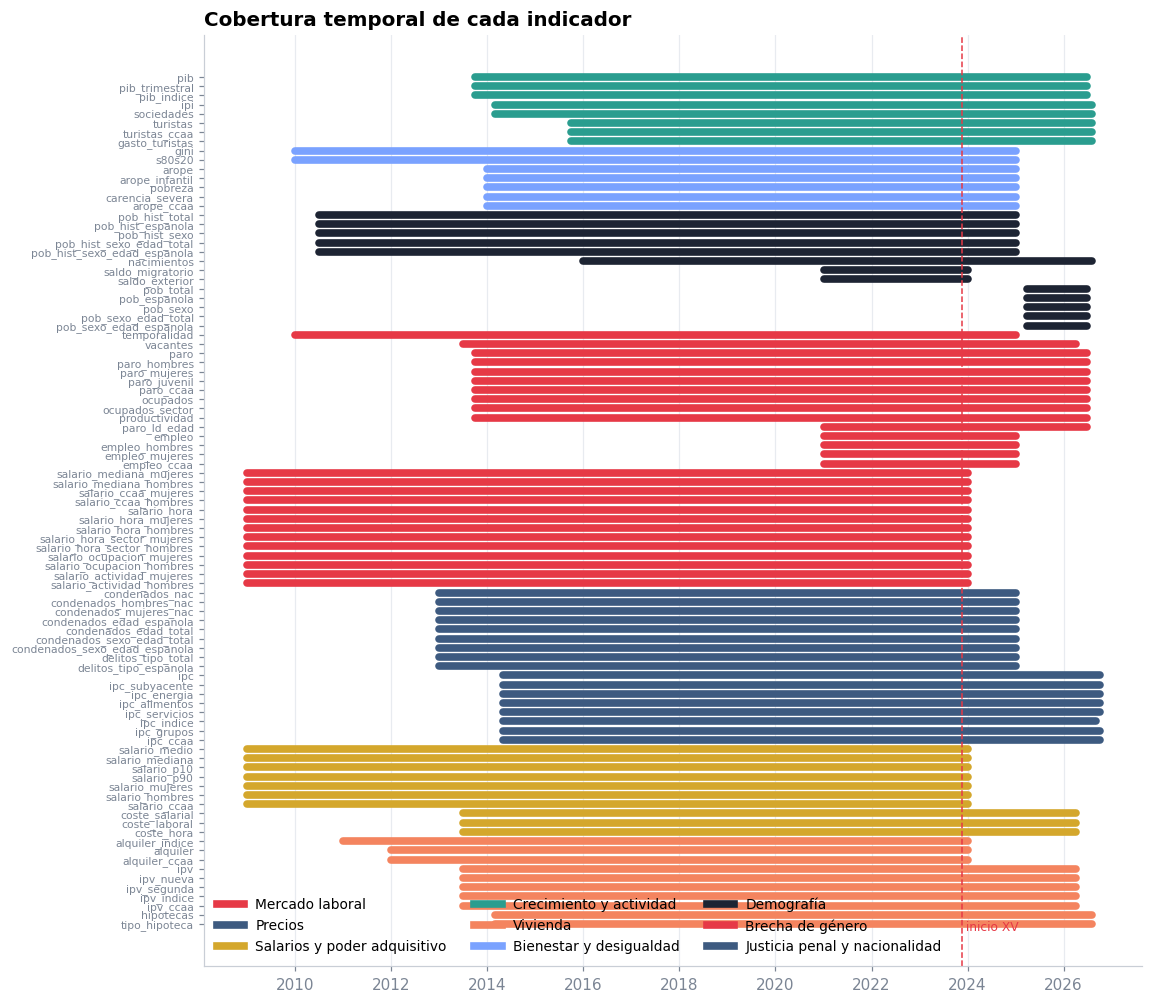

In [4]:
fig, ax = plt.subplots(figsize=(11, 11))
cv = cov[cov.n_series > 0].sort_values(["block", "first"])
colors = {b: P.SERIES_COLORS[i % len(P.SERIES_COLORS)] for i, b in enumerate(BLOCKS)}
for i, r in enumerate(cv.itertuples()):
    ax.plot([r.first, r.last], [i, i], color=colors[r.block], lw=5, solid_capstyle="round")
ax.set_yticks(range(len(cv)), cv["key"], fontsize=7)
ax.axvline(A.XV, color=C["red"], ls="--", lw=1)
ax.text(A.XV, len(cv), " inicio XV", color=C["red"], fontsize=8, va="bottom")
ax.set_title("Cobertura temporal de cada indicador")
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
handles = [plt.Line2D([], [], color=c, lw=5, label=BLOCKS[b]) for b, c in colors.items()]
ax.legend(handles=handles, loc="lower left", ncol=3)
P.save(fig, "00_cobertura"); plt.show()

**Lectura.** Casi todos los indicadores coyunturales cubren la legislatura completa. Las excepciones relevantes son el **alquiler (IPVA)**, que solo llega a 2024, y la **EAES**, cuyo último año es 2024. Lo tendremos en cuenta: para esos bloques el «balance de legislatura» es, como mucho, de su primer año.

In [5]:
# Valores perdidos y duplicados en el formato largo
checks = pd.DataFrame({
    "nulos": long_df.isna().sum(),
    "tipo": long_df.dtypes.astype(str),
})
display(checks)
dups = long_df.duplicated(["key", "dim", "fecha"]).sum()
print(f"Duplicados key-dim-fecha: {dups}")

,nulos,tipo
key,0,str
dim,0,string
fecha,0,datetime64[us]
anyo,0,int64
periodo,0,string
valor,0,float64


Duplicados key-dim-fecha: 0


<a id="3"></a>
## 3 · Scorecard de la legislatura

Para cada indicador comparamos el **último dato** con el **último dato disponible al inicio de la XV** (periodo de referencia ≤ 17/11/2023). Así evitamos mezclar información posterior a la investidura en la línea base.

La columna `improved` usa la **dirección deseable** declarada en el catálogo (p. ej. paro ↓, empleo ↑, precio de la vivienda ↓ desde el punto de vista del acceso). `xiv_delta` muestra el cambio en toda la XIV Legislatura para dar contexto.

In [6]:
sc = A.scorecard()
cols = ["block_name", "label", "unit", "start_label", "start", "latest_label", "latest", "delta", "delta_pct", "improved", "xiv_delta"]
sc[cols].style.format(precision=2, na_rep="—") \
    .map(lambda v: "color:#2a9d8f;font-weight:bold" if v is True else ("color:#e63946;font-weight:bold" if v is False else ""), subset=["improved"]) \
    .hide(axis="index")

block_name,label,unit,start_label,start,latest_label,latest,delta,delta_pct,improved,xiv_delta
Mercado laboral,Tasa de paro,%,T4 2023,11.80,T3 2026,10.18,-1.62,-13.73,True,-2.61
Mercado laboral,Tasa de paro < 25 años,%,T4 2023,28.52,T3 2026,23.33,-5.19,-18.20,True,-4.47
Mercado laboral,Tasa de empleo 20-64,%,2023,70.55,2025,72.39,1.84,2.61,True,—
Mercado laboral,Ocupados (EPA),miles,T4 2023,21389.70,T3 2026,22852.60,1462.90,6.84,True,1708.40
Mercado laboral,Asalariados con contrato temporal,%,2023,17.20,2025,15.30,-1.90,-11.05,True,-6.90
Precios,IPC general (var. anual),%,nov 2023,3.20,oct 2026,4.90,1.70,53.12,False,2.10
Precios,IPC subyacente (var. anual),%,nov 2023,4.50,oct 2026,3.10,-1.40,-31.11,True,3.50
Crecimiento y actividad,"PIB (var. anual, volumen)",%,T4 2023,2.20,T3 2026,2.66,0.46,21.10,True,6.38
Crecimiento y actividad,Producción industrial (var. anual),%,nov 2023,0.30,ago 2026,1.60,1.30,433.33,True,4.60
Salarios y poder adquisitivo,Coste salarial por trabajador y mes,€,T4 2023,2359.38,T2 2026,2512.68,153.30,6.50,True,469.60


Los cambios tienen unidades distintas (pp, €, índices), así que no son comparables directamente. Para ponerlos en una misma escala los **normalizamos por la volatilidad histórica** de cada serie: cuántas desviaciones típicas (de 2014 en adelante) se ha movido el indicador, con signo positivo si el movimiento es una mejora.

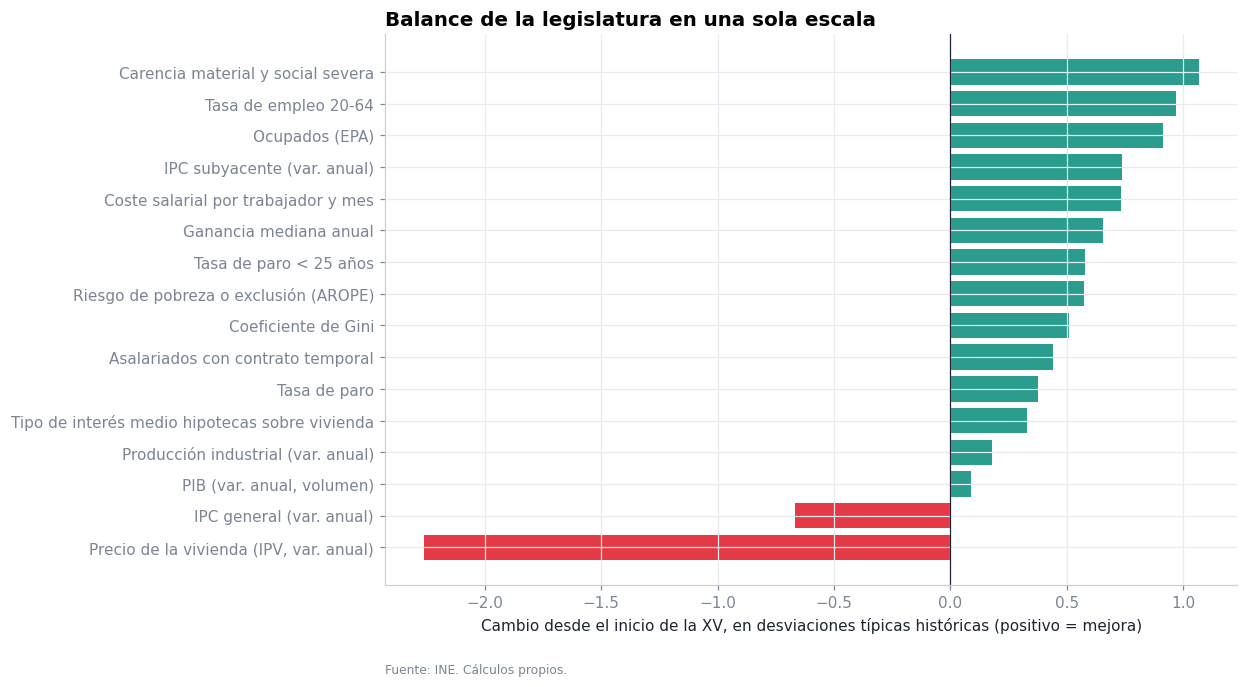

14 de 16 indicadores mejoran desde el inicio de la legislatura.


In [7]:
def standardized_change(row):
    s = A.series(row.key)
    s = s[s.index >= "2014-01-01"]
    z = row.delta / s.std()
    return z if row.better == "up" else -z

sc["z_mejora"] = sc.apply(standardized_change, axis=1)
z = sc.set_index("label")["z_mejora"].sort_values()
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(z.index, z.values, color=[C["green"] if v > 0 else C["red"] for v in z.values])
ax.axvline(0, color=C["ink"], lw=0.8)
ax.set_xlabel("Cambio desde el inicio de la XV, en desviaciones típicas históricas (positivo = mejora)")
ax.set_title("Balance de la legislatura en una sola escala")
P.source(ax, "INE. Cálculos propios."); P.save(fig, "01_balance"); plt.show()
print(f"{(sc.improved == True).sum()} de {sc.improved.notna().sum()} indicadores mejoran desde el inicio de la legislatura.")

**Lectura.** El balance está dominado por **mejoras en el mercado laboral** (paro, paro juvenil, ocupación, temporalidad) y en algunos indicadores de **bienestar** (AROPE, carencia severa, Gini). Los dos grandes **frentes negativos** son la **inflación general**, que ha repuntado por la energía, y sobre todo el **precio de la vivienda**, que se mueve muy por encima de su volatilidad habitual.

<a id="4"></a>
## 4 · Mercado laboral

La **Encuesta de Población Activa (EPA)** es la fuente de referencia: encuesta trimestral a ~65.000 hogares. Ojo: no confundir con el paro registrado (SEPE) ni con la afiliación a la Seguridad Social, que son registros administrativos.

### 4.1 Tasa de paro total y por sexo

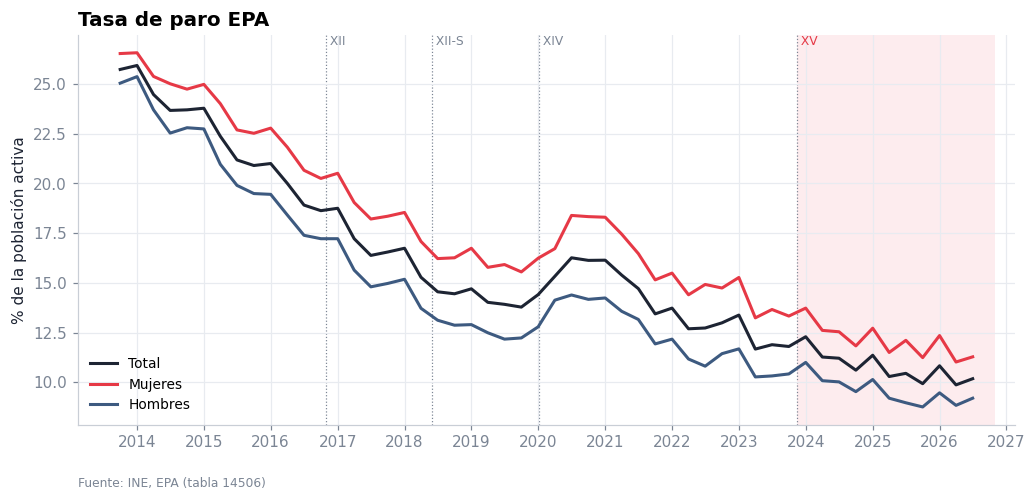

Paro: 11.80% → 10.18% (-1.62 pp) · mínimo de la serie: 9.87%


In [8]:
fig, ax = plt.subplots()
for key, lab, col in [("paro", "Total", C["ink"]), ("paro_mujeres", "Mujeres", C["red"]), ("paro_hombres", "Hombres", C["blue"])]:
    s = A.series(key); ax.plot(s.index, s.values, label=lab, color=col)
P.shade_legislatures(ax); ax.set_ylabel("% de la población activa")
ax.set_title("Tasa de paro EPA"); ax.legend(); P.source(ax, "INE, EPA (tabla 14506)")
P.save(fig, "02_paro"); plt.show()
k = A.kpi("paro"); print(f"Paro: {k.start:.2f}% → {k.latest:.2f}% ({k.delta:+.2f} pp) · mínimo de la serie: {A.series('paro').min():.2f}%")

**Lectura.** El paro mantiene la **tendencia descendente iniciada en 2013**, con el paréntesis del COVID en 2020. En la XV baja de forma sostenida y las oscilaciones trimestrales responden a la estacionalidad (la serie no está desestacionalizada: el T1 suele ser peor y el T2-T3 mejor por el turismo). La **brecha entre mujeres y hombres** persiste en torno a 2 pp, aunque se ha estrechado respecto a los 3-4 pp de 2016-2022.

### 4.2 Paro juvenil y de larga duración

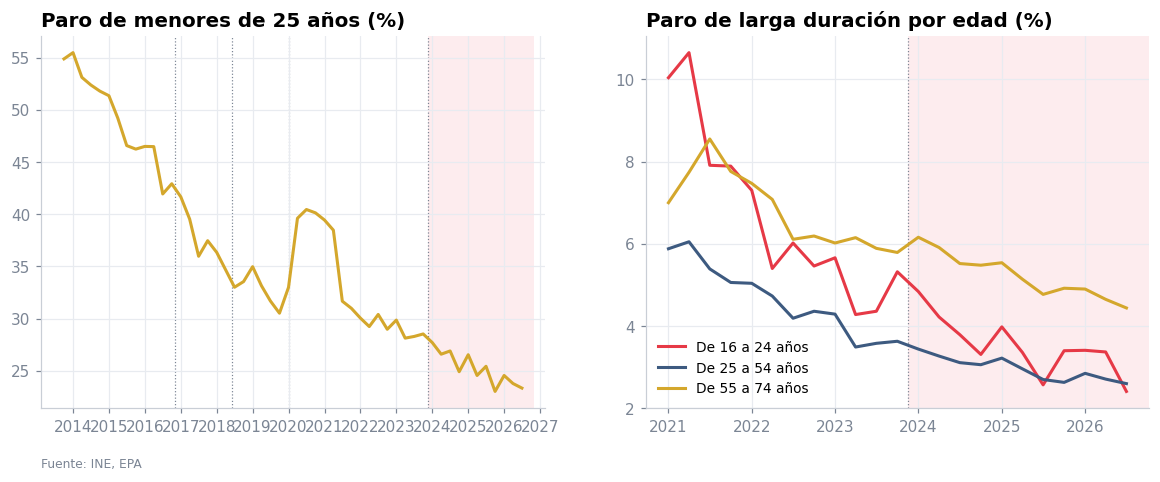

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
s = A.series("paro_juvenil"); axes[0].plot(s.index, s.values, color=C["gold"])
P.shade_legislatures(axes[0], labels=False); axes[0].set_title("Paro de menores de 25 años (%)")
ld = A.wide("paro_ld_edad")
for c in ld: axes[1].plot(ld.index, ld[c], label=c)
axes[1].set_title("Paro de larga duración por edad (%)"); axes[1].legend()
P.shade_legislatures(axes[1], labels=False)
P.source(axes[0], "INE, EPA"); P.save(fig, "03_paro_juvenil"); plt.show()

**Lectura.** El paro juvenil cae con fuerza pero sigue siendo **más del doble** de la media: es el problema estructural más persistente del mercado laboral español. El paro de larga duración afecta especialmente a los **mayores de 55**, colectivo con más dificultades de reinserción.

### 4.3 Ocupación: cuánto empleo y en qué sectores

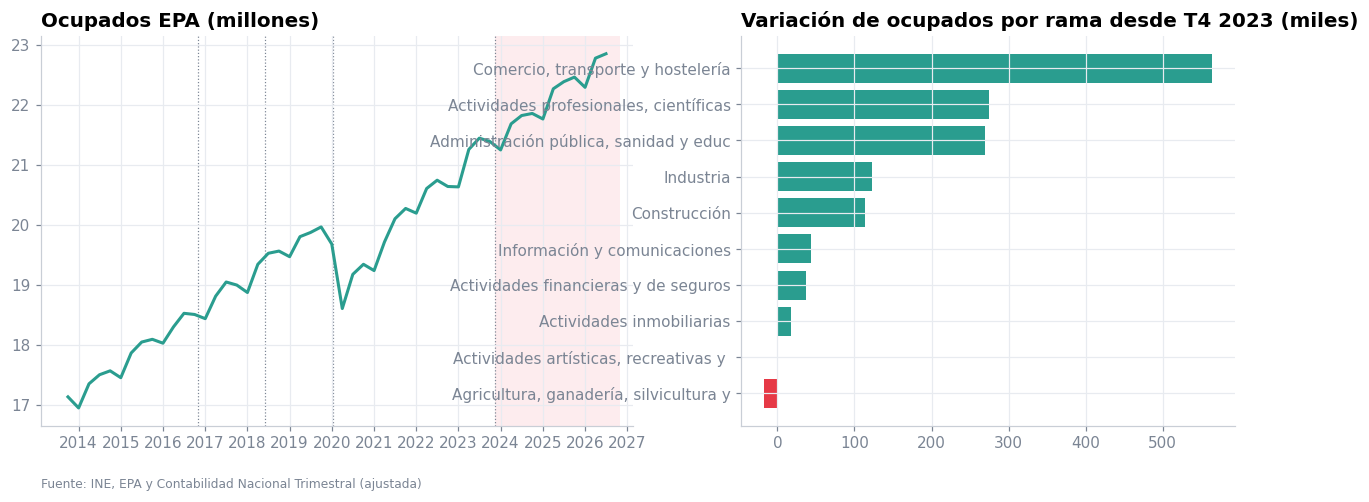

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
s = A.series("ocupados") / 1000
axes[0].plot(s.index, s.values, color=C["green"]); P.shade_legislatures(axes[0], labels=False)
axes[0].set_title("Ocupados EPA (millones)")

sec = A.wide("ocupados_sector").drop(columns=["Total CNAE", "Total Nacional", "Servicios", "Industria manufacturera"], errors="ignore")
start = sec[sec.index <= A.XV].iloc[-1]; last = sec.iloc[-1]
chg = (last - start).sort_values()
axes[1].barh([c[:38] for c in chg.index], chg.values, color=[C["green"] if v > 0 else C["red"] for v in chg.values])
axes[1].set_title("Variación de ocupados por rama desde T4 2023 (miles)")
P.source(axes[0], "INE, EPA y Contabilidad Nacional Trimestral (ajustada)"); P.save(fig, "04_ocupados"); plt.show()

**Lectura.** La ocupación marca **máximos históricos** en la serie. Por ramas (Contabilidad Nacional, datos desestacionalizados), el empleo crece sobre todo en **servicios profesionales, administración pública/sanidad/educación y comercio-transporte-hostelería**: un crecimiento intensivo en servicios, con menor aportación de la industria.

### 4.4 Calidad del empleo: temporalidad

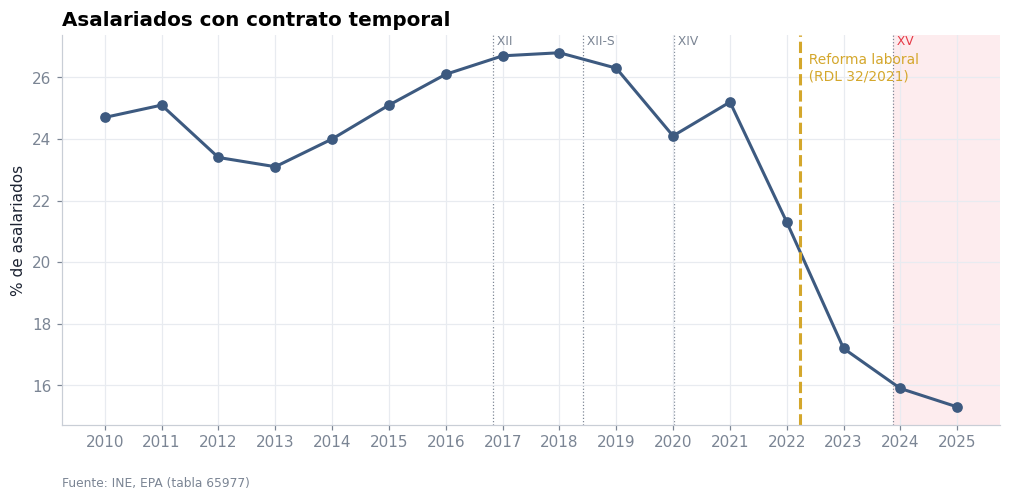

In [11]:
fig, ax = plt.subplots()
s = A.series("temporalidad")
ax.plot(s.index, s.values, marker="o", color=C["blue"])
ax.axvline(pd.Timestamp("2022-03-30"), color=C["gold"], ls="--")
ax.text(pd.Timestamp("2022-03-30"), s.max(), "  Reforma laboral\n  (RDL 32/2021)", color=C["gold"], fontsize=9, va="top")
P.shade_legislatures(ax); ax.set_ylabel("% de asalariados"); ax.set_title("Asalariados con contrato temporal")
P.source(ax, "INE, EPA (tabla 65977)"); P.save(fig, "05_temporalidad"); plt.show()

**Lectura.** El gran cambio estructural es anterior a la XV: la **reforma laboral de 2022** desplomó la temporalidad (de ~25% a ~17%). En la XV la tendencia continúa a la baja, aunque con menor intensidad. Parte del empleo «temporal» se ha transformado en **fijo discontinuo**, que la EPA clasifica como indefinido.

### 4.5 Tensión del mercado: curva de Beveridge

La curva de Beveridge relaciona **vacantes** y **paro**. Desplazamientos hacia abajo-derecha indican más paro y menos vacantes (recesión); hacia arriba-izquierda, un mercado más tenso. Si la curva se desplaza hacia fuera, señala problemas de emparejamiento entre oferta y demanda.

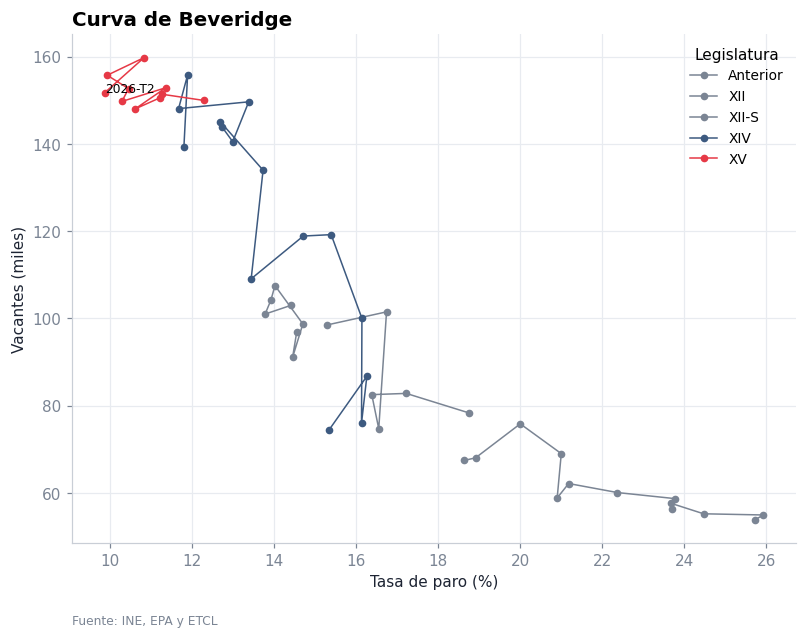

In [12]:
p = A.quarterly_panel()[["paro", "vacantes", "legislatura"]].dropna()
fig, ax = plt.subplots(figsize=(8.5, 6))
for leg, g in p.groupby("legislatura"):
    ax.plot(g["paro"], g["vacantes"] / 1000, marker="o", ms=4, lw=1, label=leg,
            color={"XV": C["red"], "XIV": C["blue"]}.get(leg, C["muted"]))
last = p.iloc[-1]; ax.annotate(f"{p.index[-1]:%Y-T}{(p.index[-1].month-1)//3+1}", (last.paro, last.vacantes/1000), fontsize=8)
ax.set_xlabel("Tasa de paro (%)"); ax.set_ylabel("Vacantes (miles)"); ax.set_title("Curva de Beveridge")
ax.legend(title="Legislatura"); P.source(ax, "INE, EPA y ETCL"); P.save(fig, "06_beveridge"); plt.show()

**Lectura.** Desde 2021 el mercado laboral se ha desplazado hacia **menos paro con más vacantes**: un mercado más tenso, en el que a las empresas les cuesta más cubrir puestos. Es coherente con la caída del paro y con la presión al alza de los salarios.

### 4.6 Productividad y costes laborales unitarios

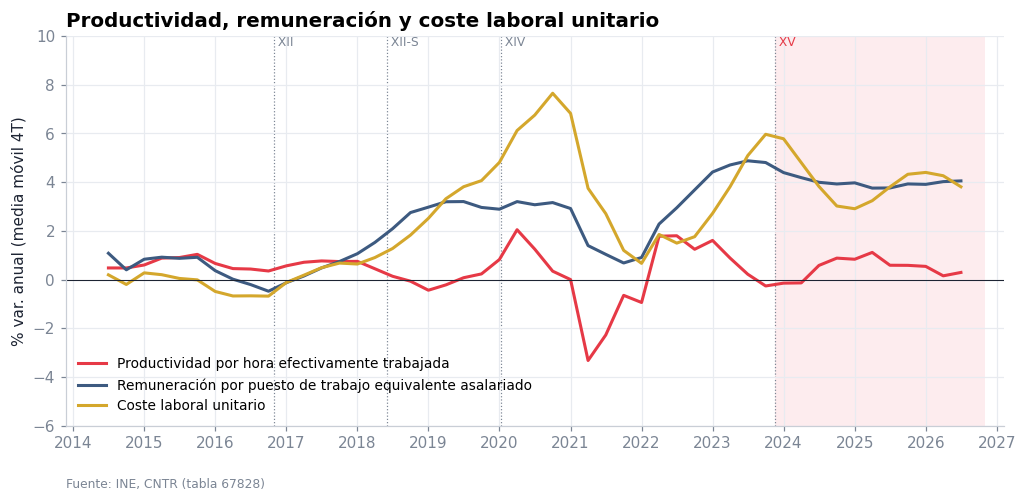

In [13]:
pr = A.wide("productividad")
fig, ax = plt.subplots()
for c in ["Productividad por hora efectivamente trabajada", "Remuneración por puesto de trabajo equivalente asalariado", "Coste laboral unitario"]:
    ax.plot(pr.index, pr[c].rolling(4).mean(), label=c)
ax.axhline(0, color=C["ink"], lw=0.7); P.shade_legislatures(ax, start="2016-01-01")
ax.set_ylim(-6, 10); ax.set_ylabel("% var. anual (media móvil 4T)"); ax.legend()
ax.set_title("Productividad, remuneración y coste laboral unitario"); P.source(ax, "INE, CNTR (tabla 67828)")
P.save(fig, "07_productividad"); plt.show()

**Lectura.** La **productividad por hora apenas crece** (en torno a 0%): el crecimiento del PIB se explica casi totalmente por **más empleo**, no por más producción por hora. Como la remuneración por asalariado sube ~4%, el **coste laboral unitario** aumenta, lo que a medio plazo erosiona competitividad. Es uno de los puntos débiles estructurales más claros.

<a id="5"></a>
## 5 · Precios e inflación

El **IPC** mide la variación de precios de una cesta representativa. La **subyacente** excluye alimentos no elaborados y energía, los componentes más volátiles, por lo que refleja mejor las presiones de fondo.

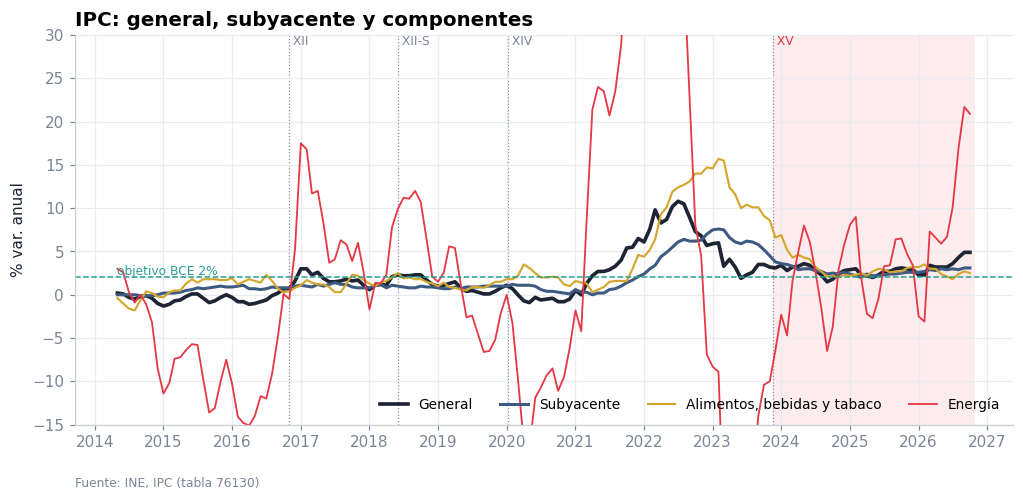

IPC oct 2026: 4.9% · subyacente 3.1% · energía 20.9%


In [14]:
fig, ax = plt.subplots()
for key, lab, col, lw in [("ipc", "General", C["ink"], 2.4), ("ipc_subyacente", "Subyacente", C["blue"], 2),
                          ("ipc_alimentos", "Alimentos, bebidas y tabaco", C["gold"], 1.4), ("ipc_energia", "Energía", C["red"], 1.2)]:
    s = A.series(key); ax.plot(s.index, s.values, label=lab, color=col, lw=lw)
ax.axhline(2, color=C["green"], ls="--", lw=1); ax.text(A.series("ipc").index[0], 2.3, "objetivo BCE 2%", color=C["green"], fontsize=8)
ax.set_ylim(-15, 30); P.shade_legislatures(ax); ax.set_ylabel("% var. anual")
ax.set_title("IPC: general, subyacente y componentes"); ax.legend(ncol=4); P.source(ax, "INE, IPC (tabla 76130)")
P.save(fig, "08_ipc"); plt.show()
k, ks, ke = A.kpi("ipc"), A.kpi("ipc_subyacente"), A.kpi("ipc_energia")
print(f"IPC {k.latest_label}: {k.latest}% · subyacente {ks.latest}% · energía {ke.latest}%")

**Lectura.** La XV arranca con la inflación ya bajando tras el pico de 2022 (10,8% en julio de 2022). En 2026 se produce un **repunte del IPC general impulsado por la energía**, mientras que la **subyacente se modera**. Es un patrón de *shock de oferta energético*: afecta mucho al bolsillo (carburantes, electricidad) pero de momento no se traslada con la misma intensidad al resto de precios.

### 5.1 ¿Dónde se concentra la inflación? Mapa de calor por grupos ECOICOP

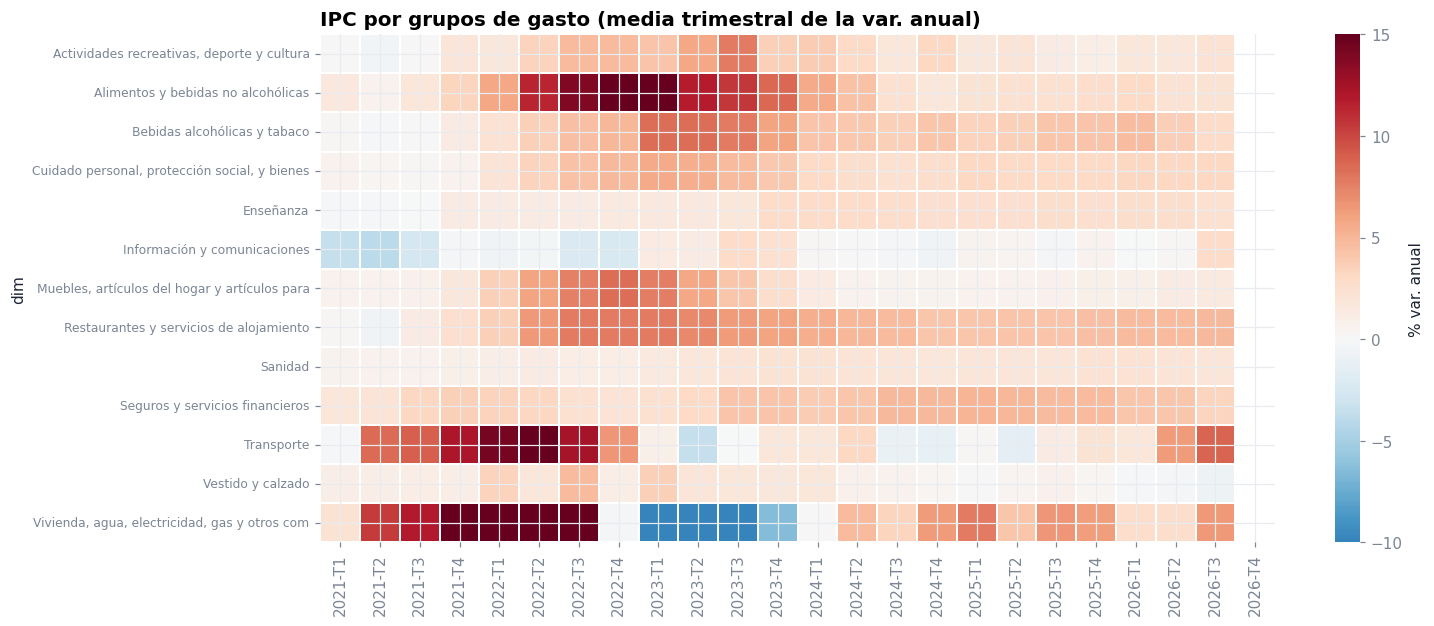

In [15]:
g = A.wide("ipc_grupos").drop(columns=["Índice general"], errors="ignore")
g = g[g.index >= "2021-01-01"].resample("QS").mean()
g.index = [f"{d.year}-T{(d.month-1)//3+1}" for d in g.index]
fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(g.T, cmap="RdBu_r", center=0, vmin=-10, vmax=15, ax=ax, cbar_kws={"label": "% var. anual"}, linewidths=0.3)
ax.set_yticklabels([t.get_text()[:45] for t in ax.get_yticklabels()], fontsize=8)
ax.set_title("IPC por grupos de gasto (media trimestral de la var. anual)"); ax.set_xlabel("")
P.save(fig, "09_ipc_heatmap"); plt.show()

**Lectura.** El mapa muestra dos episodios: la **gran ola de 2022** (vivienda-energía, transporte y alimentos en rojo intenso) y el **repunte reciente** concentrado en **transporte** y **vivienda, agua, electricidad y gas**. Alimentos, que fue el gran problema de 2023, se ha normalizado. Servicios como restauración muestran inflación persistente pero moderada.

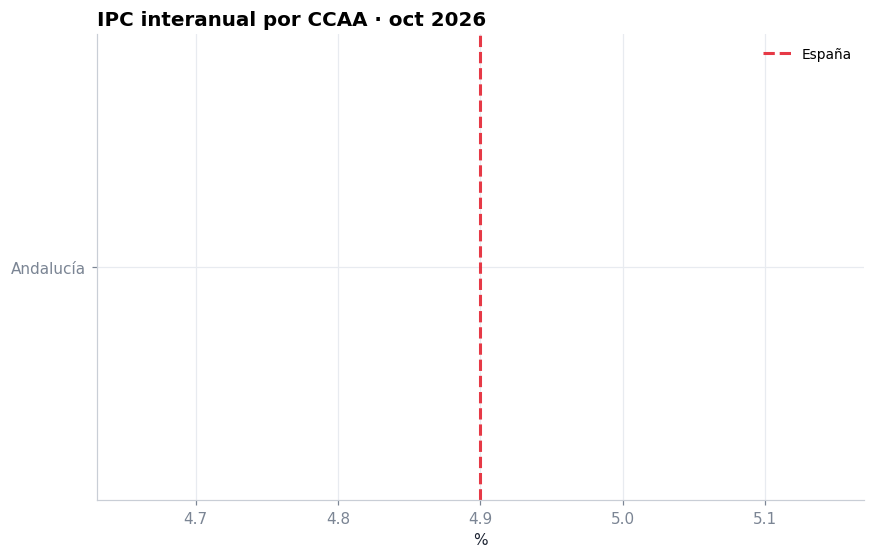

In [16]:
ccaa_ipc = A.wide("ipc_ccaa").iloc[-1].drop("España").sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(ccaa_ipc.index, ccaa_ipc.values, color=C["sky"]); ax.axvline(A.kpi("ipc").latest, color=C["red"], ls="--", label="España")
ax.set_title(f"IPC interanual por CCAA · {A.period_label(A.wide('ipc_ccaa').index[-1], 'M')}"); ax.set_xlabel("%"); ax.legend()
P.save(fig, "10_ipc_ccaa"); plt.show()

<a id="6"></a>
## 6 · Salarios y poder adquisitivo

Usamos dos fuentes complementarias:

- **ETCL** (Encuesta Trimestral de Coste Laboral): coste salarial medio por trabajador y mes. Es trimestral y muy actual, pero está afectada por la estacionalidad de las pagas extra → usamos **media móvil de 4 trimestres**.
- **EAES** (Encuesta Anual de Estructura Salarial): ganancia anual por trabajador con distribución (media, mediana, percentiles). Más rica, pero con 2 años de retraso.

El **salario real** se obtiene deflactando el salario nominal con el IPC.

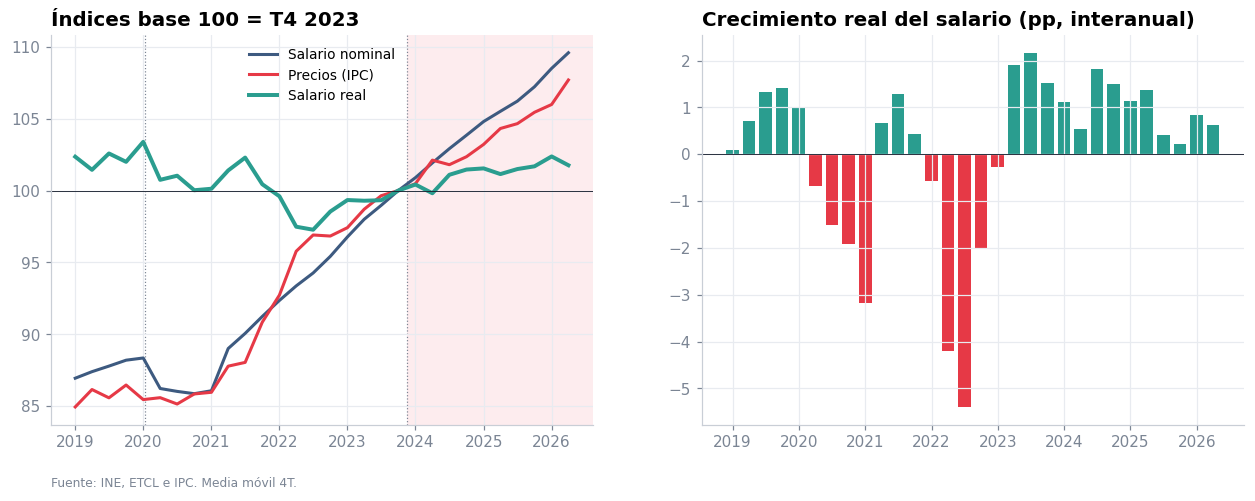

Desde el inicio de la XV: nominal +9.6% · IPC +7.7% · real +1.8%


In [17]:
rw = A.real_wages()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
r = rw[rw.index >= "2019-01-01"]
axes[0].plot(r.index, r.nominal_idx, label="Salario nominal", color=C["blue"])
axes[0].plot(r.index, r.ipc_idx, label="Precios (IPC)", color=C["red"])
axes[0].plot(r.index, r.real_idx, label="Salario real", color=C["green"], lw=2.6)
axes[0].axhline(100, color=C["ink"], lw=0.6); P.shade_legislatures(axes[0], labels=False)
axes[0].set_title("Índices base 100 = T4 2023"); axes[0].legend()
axes[1].bar(r.index, r.real_yoy, width=70, color=[C["green"] if v > 0 else C["red"] for v in r.real_yoy])
axes[1].set_title("Crecimiento real del salario (pp, interanual)"); axes[1].axhline(0, color=C["ink"], lw=0.6)
P.source(axes[0], "INE, ETCL e IPC. Media móvil 4T."); P.save(fig, "11_salario_real"); plt.show()
last = rw.iloc[-1]; print(f"Desde el inicio de la XV: nominal {last.nominal_idx-100:+.1f}% · IPC {last.ipc_idx-100:+.1f}% · real {last.real_idx-100:+.1f}%")

**Lectura.** Tras la fuerte **pérdida de poder adquisitivo de 2021-2022**, los salarios crecen por encima de los precios desde 2023. En la XV el salario real acumula una **ganancia modesta** (en torno a +2%). El repunte de inflación de 2026 estrecha ese margen: el salario real casi deja de crecer.

### 6.1 Distribución salarial (EAES)

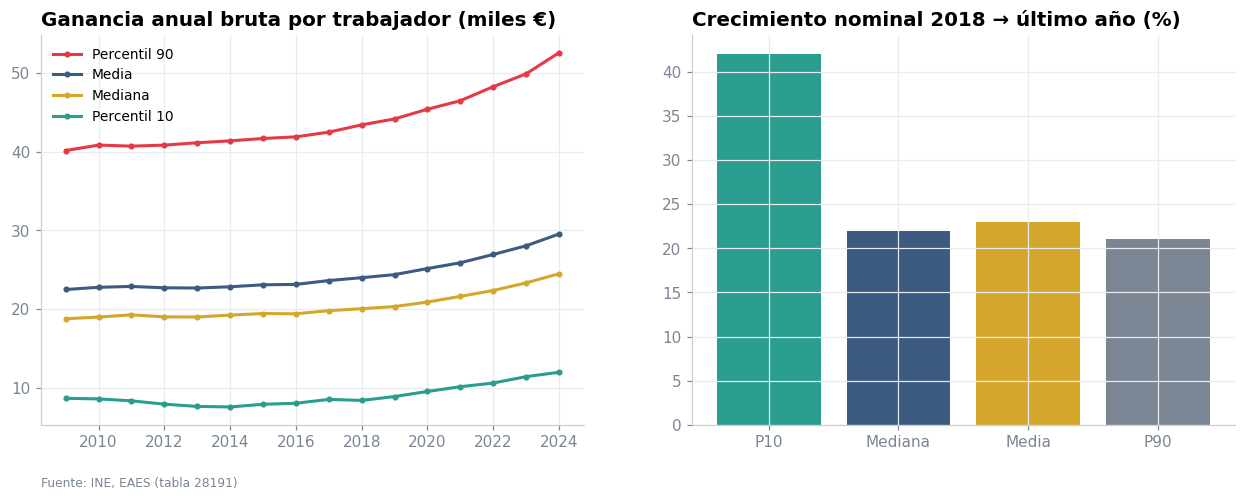

Ratio P90/P10: 4.60 (2009) → 4.37 (2024)


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for key, lab in [("salario_p90", "Percentil 90"), ("salario_medio", "Media"), ("salario_mediana", "Mediana"), ("salario_p10", "Percentil 10")]:
    s = A.series(key); axes[0].plot(s.index, s.values / 1000, marker="o", ms=3, label=lab)
axes[0].set_title("Ganancia anual bruta por trabajador (miles €)"); axes[0].legend()
p10, p90 = A.series("salario_p10"), A.series("salario_p90")
growth = pd.Series({lab: (A.series(k).iloc[-1] / A.series(k).loc["2018-01-01"] - 1) * 100
                    for k, lab in [("salario_p10", "P10"), ("salario_mediana", "Mediana"), ("salario_medio", "Media"), ("salario_p90", "P90")]})
axes[1].bar(growth.index, growth.values, color=[C["green"], C["blue"], C["gold"], C["muted"]])
axes[1].set_title("Crecimiento nominal 2018 → último año (%)")
P.source(axes[0], "INE, EAES (tabla 28191)"); P.save(fig, "12_distribucion_salarial"); plt.show()
print(f"Ratio P90/P10: {(p90/p10).iloc[0]:.2f} ({p90.index[0].year}) → {(p90/p10).iloc[-1]:.2f} ({p90.index[-1].year})")

**Lectura.** Los **salarios bajos crecen mucho más rápido** que los altos: el percentil 10 sube bastante más que la mediana o el P90 desde 2018. Es la huella de las fuertes subidas del **Salario Mínimo Interprofesional** (de 736 € en 2018 a más de 1.100 € en catorce pagas). La consecuencia es una **compresión de la distribución salarial**: el ratio P90/P10 cae.

<a id="7"></a>
## 7 · Brecha salarial de género

La **brecha salarial no ajustada** se define como `(salario hombres − salario mujeres) / salario hombres`. Tiene varias versiones y conviene no confundirlas:

| Medida | Qué captura |
|---|---|
| **Por hora** | Indicador oficial europeo (*Gender Pay Gap*, Eurostat). Neutraliza la diferencia de horas trabajadas. |
| **Anual media** | Incluye el efecto de la **jornada parcial**, mucho más frecuente entre mujeres. |
| **Anual mediana** | Menos sensible a salarios muy altos. |

Ninguna de ellas es una medida de *discriminación* (a igual trabajo, igual salario): recogen también diferencias de ocupación, sector, antigüedad y jornada. Por eso las desglosamos.

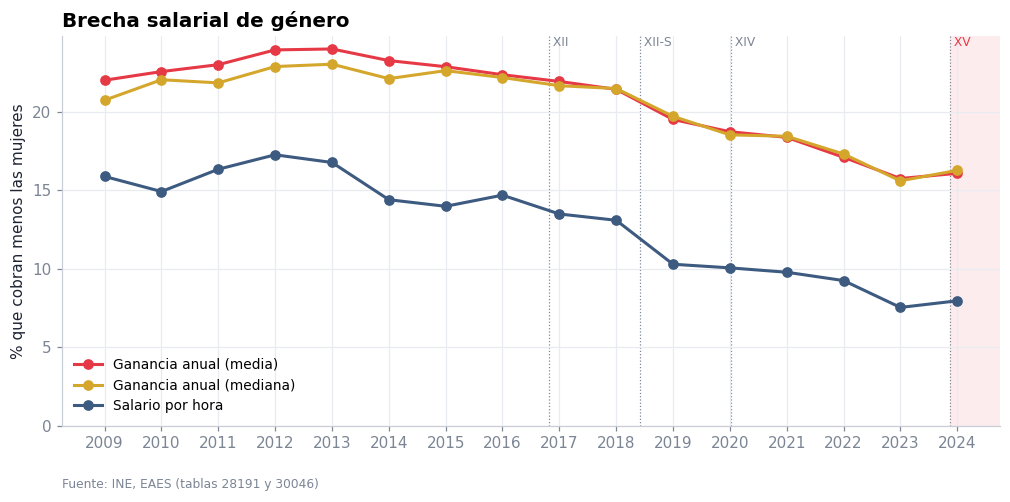

fecha,2019-01-01,2020-01-01,2021-01-01,2022-01-01,2023-01-01,2024-01-01
anual_media,19.50,18.72,18.36,17.09,15.74,16.07
anual_mediana,19.70,18.52,18.43,17.30,15.59,16.26
por_hora,10.28,10.05,9.77,9.24,7.53,7.95


In [19]:
gap = A.gender_gap()
fig, ax = plt.subplots()
for c, lab, col in [("anual_media", "Ganancia anual (media)", C["red"]), ("anual_mediana", "Ganancia anual (mediana)", C["gold"]), ("por_hora", "Salario por hora", C["blue"])]:
    ax.plot(gap.index, gap[c], marker="o", label=lab, color=col)
ax.set_ylabel("% que cobran menos las mujeres"); ax.set_ylim(0, None)
ax.set_title("Brecha salarial de género"); ax.legend(); P.shade_legislatures(ax)
P.source(ax, "INE, EAES (tablas 28191 y 30046)"); P.save(fig, "13_brecha_genero"); plt.show()
display(gap.tail(6).T)

**Lectura.** La brecha se reduce de forma clara en todas sus medidas, sobre todo desde 2018. Por hora trabajada **se reduce a la mitad**: de ~16% (2009) a ~8% (2024). En ganancia anual baja del ~22-24% a ~16%, pero sigue siendo el doble que la horaria porque las mujeres trabajan más a tiempo parcial. La diferencia entre ambas curvas es, en sí misma, una medida del **efecto de la parcialidad**.

### 7.1 ¿Dónde es mayor la brecha?

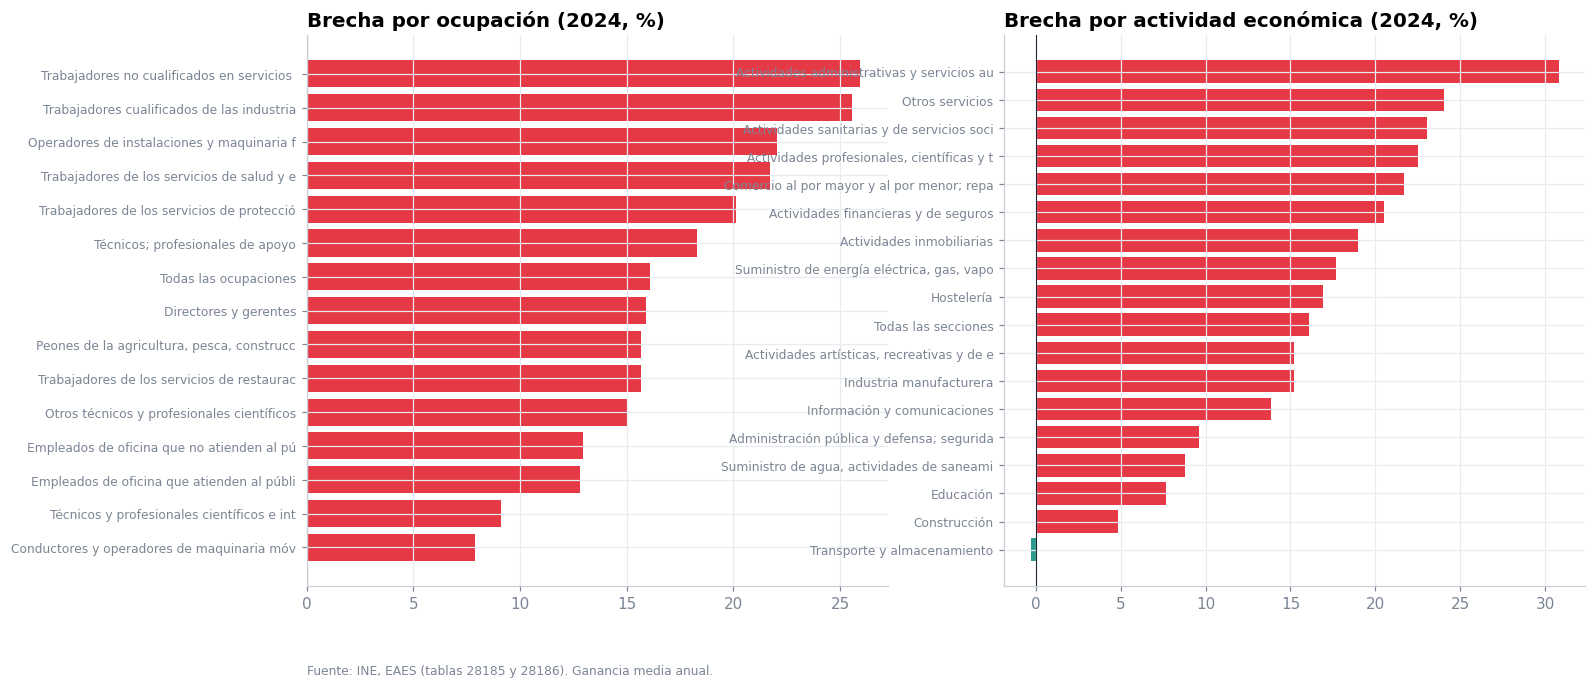

In [20]:
occ = A.gender_gap_by("salario_ocupacion"); act = A.gender_gap_by("salario_actividad")
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
o = occ.sort_values("brecha")
axes[0].barh([i[:42] for i in o.index], o.brecha, color=[C["red"] if v > 0 else C["green"] for v in o.brecha])
axes[0].set_title(f"Brecha por ocupación ({occ.attrs['year']}, %)")
a = act.sort_values("brecha")
axes[1].barh([i[:42] for i in a.index], a.brecha, color=[C["red"] if v > 0 else C["green"] for v in a.brecha])
axes[1].set_title(f"Brecha por actividad económica ({act.attrs['year']}, %)")
for ax in axes: ax.axvline(0, color=C["ink"], lw=0.7); ax.tick_params(axis="y", labelsize=8)
P.source(axes[0], "INE, EAES (tablas 28185 y 28186). Ganancia media anual."); P.save(fig, "14_brecha_ocupacion"); plt.show()

**Lectura.** La brecha es **mayor en ocupaciones poco cualificadas de servicios, en la industria manufacturera y en los cuidados** (20-26%), y **menor** entre los profesionales de salud y enseñanza (~9%). Por actividad, es mínima en **administración pública, educación y construcción**, y prácticamente nula en transporte. En construcción, la ganancia por hora de las mujeres incluso supera a la de los hombres. Esto apunta a que buena parte de la brecha agregada es **composicional**: hombres y mujeres se concentran en ocupaciones y actividades con salarios distintos y con distinta incidencia de complementos y horas extra.

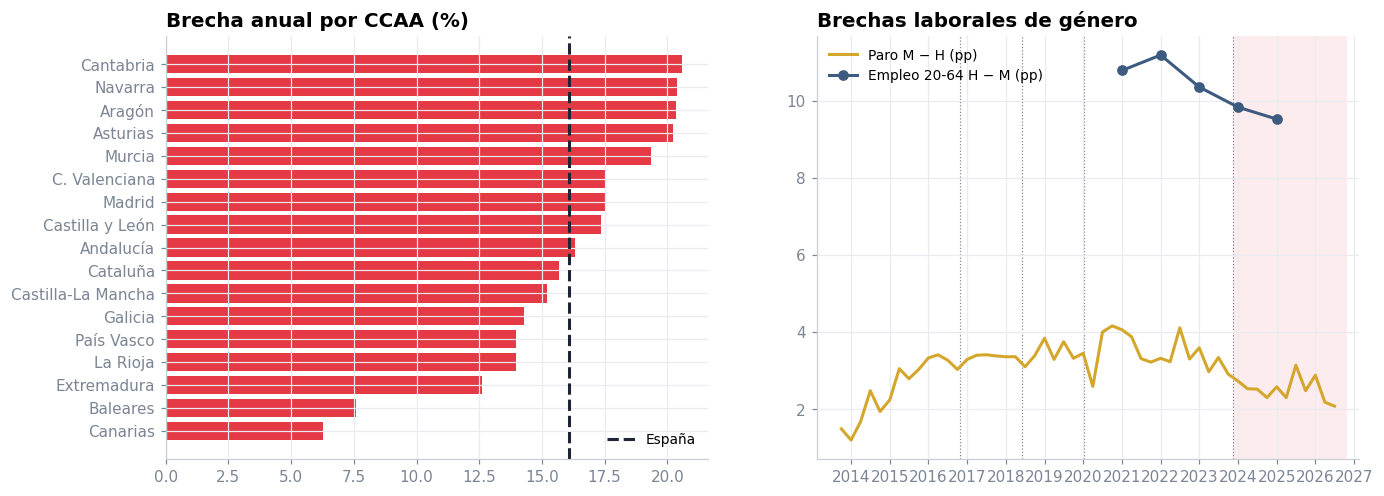

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
gccaa = A.gender_gap_ccaa().drop(["España"], errors="ignore").dropna().sort_values()
axes[0].barh(gccaa.index, gccaa.values, color=C["red"]); axes[0].axvline(A.gender_gap()["anual_media"].iloc[-1], color=C["ink"], ls="--", label="España")
axes[0].set_title("Brecha anual por CCAA (%)"); axes[0].legend()
lg = A.labour_gender()
axes[1].plot(lg.index, lg.brecha_paro_pp, color=C["gold"], label="Paro M − H (pp)")
emp = (lg.empleo_hombres - lg.empleo_mujeres).dropna()
axes[1].plot(emp.index, emp.values, marker="o", color=C["blue"], label="Empleo 20-64 H − M (pp)")
axes[1].set_title("Brechas laborales de género"); axes[1].legend(); P.shade_legislatures(axes[1], labels=False)
P.save(fig, "15_brecha_ccaa"); plt.show()

**Lectura.** Las comunidades con más **industria** (Aragón, Navarra, Asturias, Cantabria) presentan brechas mayores; las más **turísticas** (Baleares, Canarias) las menores, por la mayor homogeneidad salarial del sector. En el mercado laboral, la brecha de paro y la de tasa de empleo también se estrechan.

<a id="8"></a>
## 8 · Crecimiento y actividad

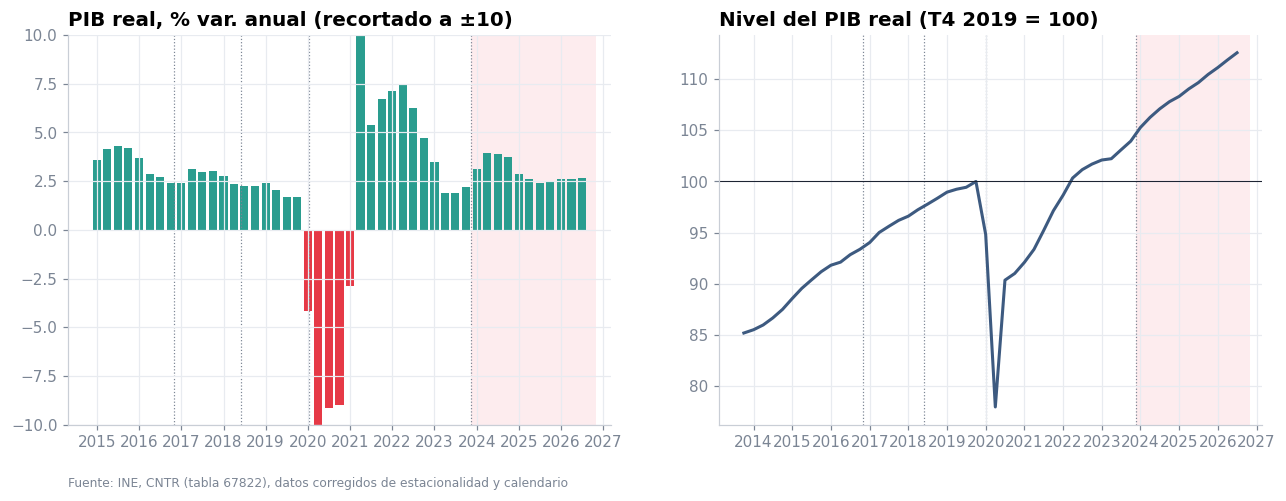

PIB real vs pre-COVID (T4 2019): +12.6%


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
s = A.series("pib"); s = s[s.index >= "2015-01-01"]
axes[0].bar(s.index, s.values, width=70, color=[C["green"] if v > 0 else C["red"] for v in s.values])
axes[0].set_ylim(-10, 10); axes[0].set_title("PIB real, % var. anual (recortado a ±10)")
P.shade_legislatures(axes[0], labels=False)
pi = A.series("pib_indice"); pi = pi / pi.loc["2019-10-01"] * 100
axes[1].plot(pi.index, pi.values, color=C["blue"]); axes[1].axhline(100, color=C["ink"], lw=0.7)
axes[1].set_title("Nivel del PIB real (T4 2019 = 100)"); P.shade_legislatures(axes[1], labels=False)
P.source(axes[0], "INE, CNTR (tabla 67822), datos corregidos de estacionalidad y calendario"); P.save(fig, "16_pib"); plt.show()
print(f"PIB real vs pre-COVID (T4 2019): {pi.iloc[-1]-100:+.1f}%")

**Lectura.** España crece en la XV a ritmos de **2,5-4% anual** (2,7% en el último trimestre), muy por encima de la media de la eurozona según Eurostat. El nivel del PIB real supera holgadamente el previo a la pandemia. Combinado con el análisis de productividad (§4.6), el crecimiento es sobre todo **extensivo**: más población, más empleo y más turismo.

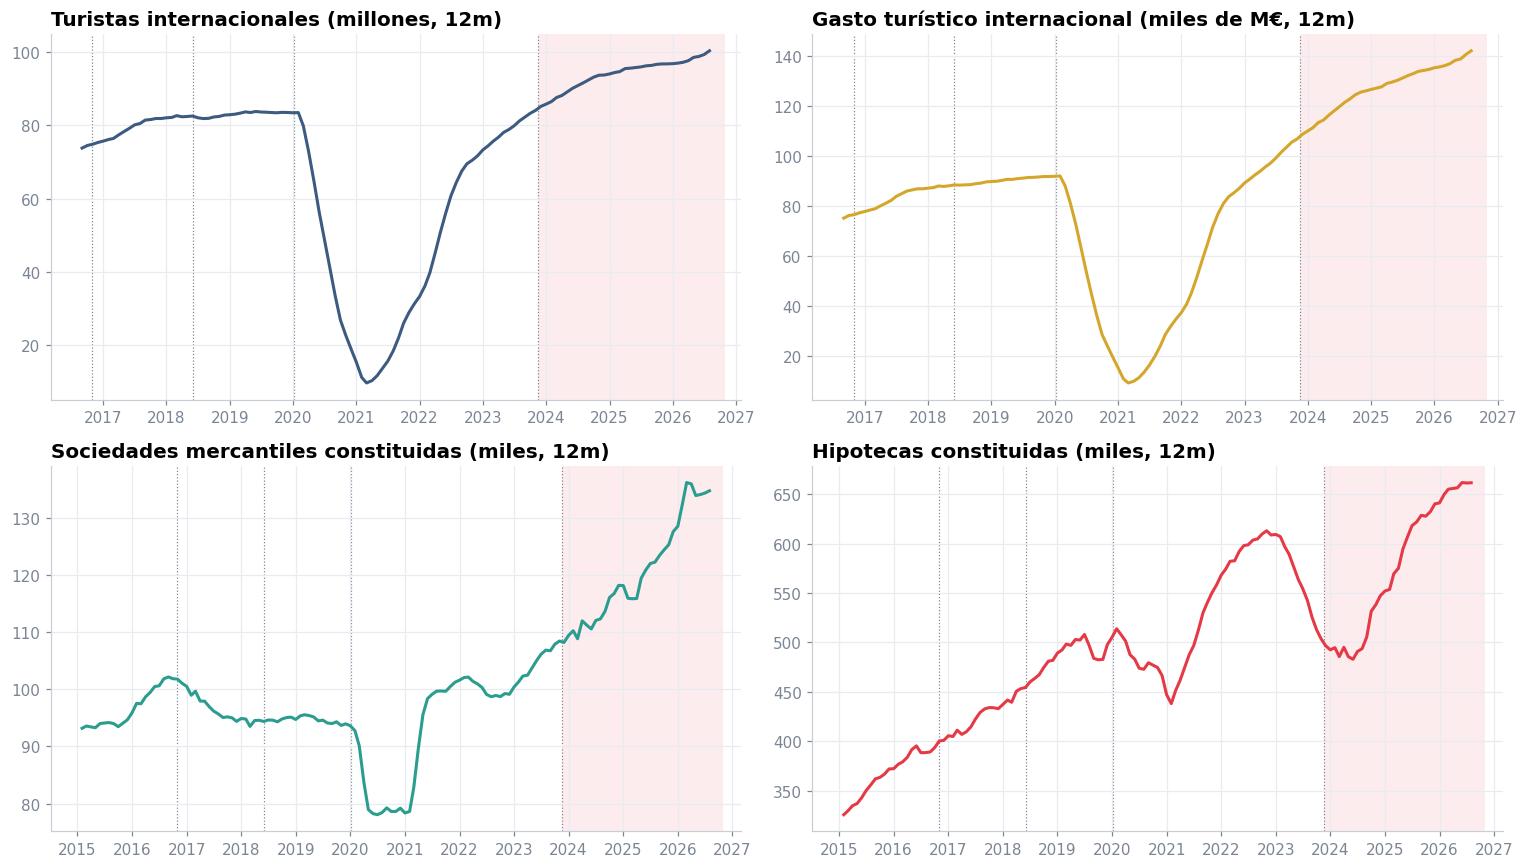

IPI ago 2026: +1.6% interanual


In [23]:
fl = A.flows_12m()
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
spec = [("turistas", "Turistas internacionales (millones, 12m)", 1e6, C["blue"]),
        ("gasto_turistas", "Gasto turístico internacional (miles de M€, 12m)", 1e3, C["gold"]),
        ("sociedades", "Sociedades mercantiles constituidas (miles, 12m)", 1e3, C["green"]),
        ("hipotecas", "Hipotecas constituidas (miles, 12m)", 1e3, C["red"])]
for ax, (k, t, d, col) in zip(axes.flat, spec):
    s = fl[k].dropna(); ax.plot(s.index, s / d, color=col); ax.set_title(t); P.shade_legislatures(ax, labels=False)
fig.tight_layout(); P.save(fig, "17_flujos"); plt.show()
ipi = A.kpi("ipi"); print(f"IPI {ipi.latest_label}: {ipi.latest:+.1f}% interanual")

**Lectura.** **Récords de turismo**: tanto en llegadas como, sobre todo, en gasto, que crece más rápido que el número de turistas. La **creación de empresas** se mantiene en niveles altos y las **hipotecas** se recuperan con fuerza desde 2024, cuando el BCE empieza a bajar tipos: es otro factor que presiona la demanda de vivienda.

<a id="9"></a>
## 9 · Vivienda

El **IPV** mide precios de compraventa de vivienda libre (escrituras notariales); el **IPVA** mide alquileres a partir de datos fiscales (IRPF), por eso llega con mucho retraso.

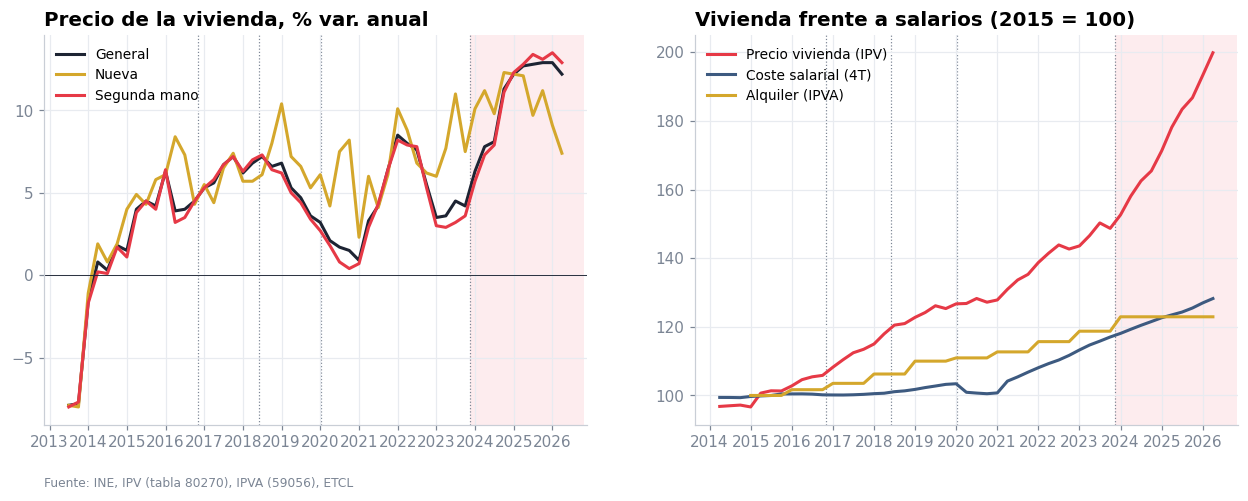

Índice de esfuerzo (IPV/salario, 2015=100): 156


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for key, lab, col in [("ipv", "General", C["ink"]), ("ipv_nueva", "Nueva", C["gold"]), ("ipv_segunda", "Segunda mano", C["red"])]:
    s = A.series(key); axes[0].plot(s.index, s.values, label=lab, color=col)
axes[0].axhline(0, color=C["ink"], lw=0.6); axes[0].set_title("Precio de la vivienda, % var. anual"); axes[0].legend()
P.shade_legislatures(axes[0], labels=False)
ha = A.housing_affordability()
axes[1].plot(ha.index, ha.ipv_idx, label="Precio vivienda (IPV)", color=C["red"])
axes[1].plot(ha.index, ha.salario_idx, label="Coste salarial (4T)", color=C["blue"])
if "alquiler_idx" in ha: axes[1].plot(ha.index, ha.alquiler_idx, label="Alquiler (IPVA)", color=C["gold"])
axes[1].set_title("Vivienda frente a salarios (2015 = 100)"); axes[1].legend(); P.shade_legislatures(axes[1], labels=False)
P.source(axes[0], "INE, IPV (tabla 80270), IPVA (59056), ETCL"); P.save(fig, "18_vivienda"); plt.show()
print(f"Índice de esfuerzo (IPV/salario, 2015=100): {ha.esfuerzo.iloc[-1]:.0f}")

**Lectura.** Es el **indicador más negativo de la legislatura**. El precio de la vivienda se ha **acelerado** desde el ~4% de finales de 2023 a **dobles dígitos**, empujado sobre todo por la **segunda mano**. Desde 2015 la vivienda se ha encarecido aproximadamente el doble mientras los salarios han subido menos de un 30%: el **índice de esfuerzo** supera en más de un 50% al de 2015. La causa de fondo combina una **oferta nueva muy escasa** con fuerte **creación de hogares** (inmigración) y crédito más barato.

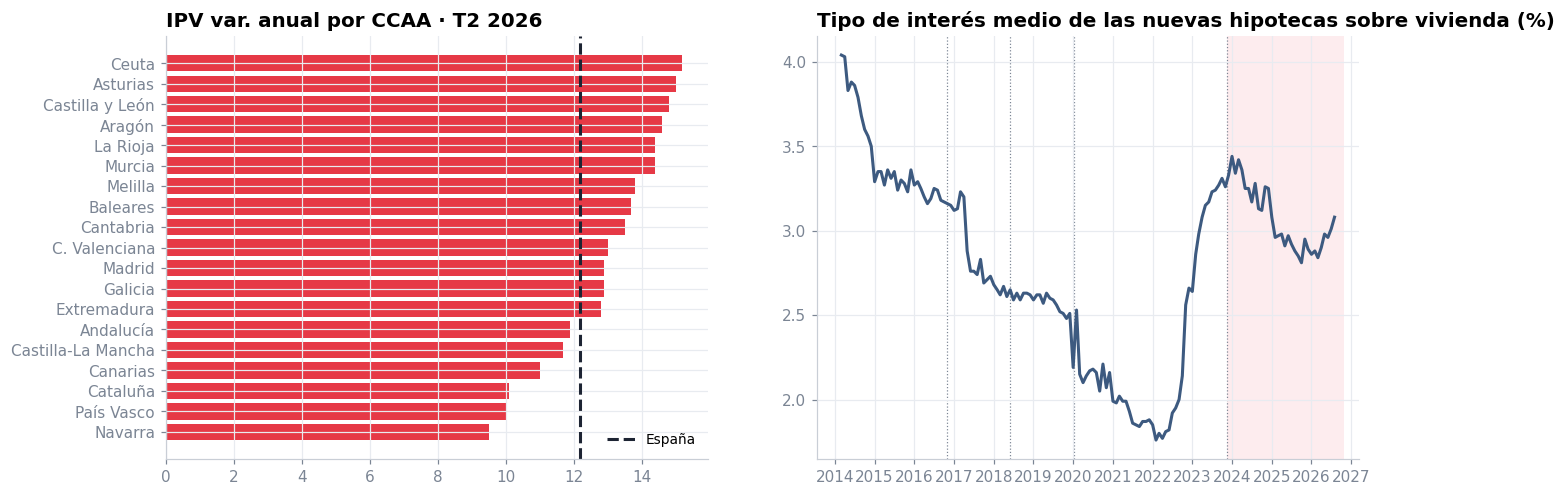

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
v = A.wide("ipv_ccaa").iloc[-1].drop("España").sort_values()
axes[0].barh(v.index, v.values, color=C["red"]); axes[0].axvline(A.kpi("ipv").latest, color=C["ink"], ls="--", label="España")
axes[0].set_title(f"IPV var. anual por CCAA · {A.period_label(A.wide('ipv_ccaa').index[-1], 'Q')}"); axes[0].legend()
th = A.series("tipo_hipoteca"); axes[1].plot(th.index, th.values, color=C["blue"])
axes[1].set_title("Tipo de interés medio de las nuevas hipotecas sobre vivienda (%)"); P.shade_legislatures(axes[1], labels=False)
P.save(fig, "19_vivienda_ccaa"); plt.show()

<a id="10"></a>
## 10 · Bienestar y desigualdad

Fuente: **Encuesta de Condiciones de Vida (ECV)**. Atención al desfase: la ECV del año *t* usa la renta del año *t-1*. La ECV 2025 es la primera que refleja de lleno el primer año de la XV (rentas de 2024).

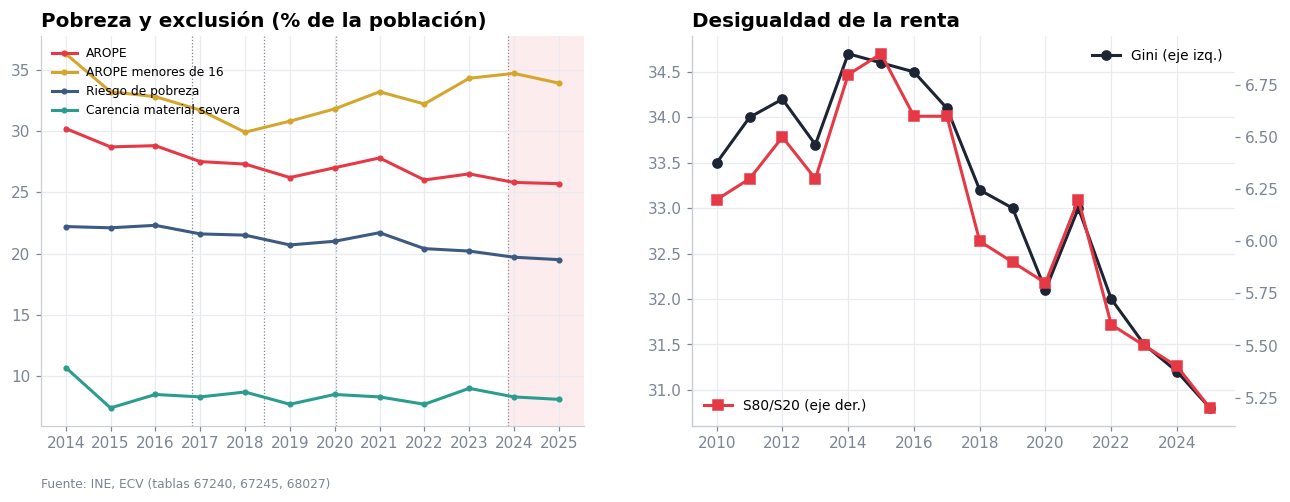

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for key, lab, col in [("arope", "AROPE", C["red"]), ("arope_infantil", "AROPE menores de 16", C["gold"]),
                      ("pobreza", "Riesgo de pobreza", C["blue"]), ("carencia_severa", "Carencia material severa", C["green"])]:
    s = A.series(key); axes[0].plot(s.index, s.values, marker="o", ms=3, label=lab, color=col)
axes[0].set_title("Pobreza y exclusión (% de la población)"); axes[0].legend(fontsize=8); P.shade_legislatures(axes[0], labels=False)
g, s8 = A.series("gini"), A.series("s80s20")
axes[1].plot(g.index, g.values, marker="o", color=C["ink"], label="Gini (eje izq.)")
ax2 = axes[1].twinx(); ax2.plot(s8.index, s8.values, marker="s", color=C["red"], label="S80/S20 (eje der.)"); ax2.grid(False)
axes[1].set_title("Desigualdad de la renta"); axes[1].legend(loc="upper right"); ax2.legend(loc="lower left")
P.source(axes[0], "INE, ECV (tablas 67240, 67245, 68027)"); P.save(fig, "20_bienestar"); plt.show()

**Lectura.** Mejora **lenta pero continua**: AROPE, tasa de pobreza y desigualdad (Gini, S80/S20) marcan en 2025 los **mínimos de la serie**. La carencia material severa, en cambio, está estancada en torno al 8%. Aun así, **1 de cada 4 residentes** sigue en riesgo de pobreza o exclusión, y la **pobreza infantil** (~34%) no mejora: está por encima de la de 2018 y es uno de los peores registros de la UE.

<a id="11"></a>
## 11 · Demografía

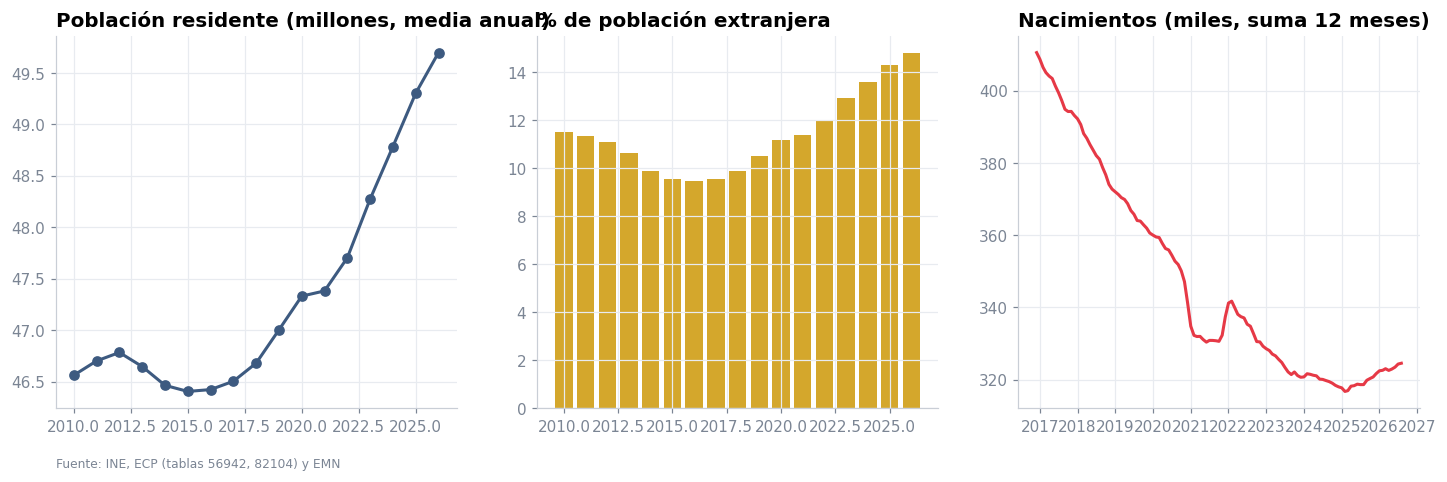

Población 2026: 49.70 M · extranjeros 14.8%


In [27]:
pop = A.population_by_nationality()
tot = pop[pop.nacionalidad == "total"]["Todas las edades"]; ext = pop[pop.nacionalidad == "extranjera"]["Todas las edades"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
axes[0].plot(tot.index, tot / 1e6, marker="o", color=C["blue"]); axes[0].set_title("Población residente (millones, media anual)")
axes[1].bar(ext.index, ext / tot * 100, color=C["gold"]); axes[1].set_title("% de población extranjera")
n = A.flows_12m()["nacimientos"].dropna(); axes[2].plot(n.index, n / 1000, color=C["red"]); axes[2].set_title("Nacimientos (miles, suma 12 meses)")
P.source(axes[0], "INE, ECP (tablas 56942, 82104) y EMN"); P.save(fig, "21_demografia"); plt.show()
print(f"Población {tot.index[-1]}: {tot.iloc[-1]/1e6:.2f} M · extranjeros {ext.iloc[-1]/tot.iloc[-1]*100:.1f}%")

**Lectura.** España roza los **50 millones** de habitantes (49,7 M de media en 2026), con un crecimiento **casi totalmente explicado por la inmigración**: el peso de la población extranjera pasa del ~9,5% de 2016 a ~15%. Mientras, los **nacimientos se estancan cerca de mínimos**: unos 320.000 al año, un 22% menos que en 2016, con un leve repunte en 2025 tras el mínimo de 2024. La inmigración sostiene el crecimiento del empleo y de la población activa, pero también presiona la demanda de vivienda.

<a id="12"></a>
## 12 · Justicia penal y nacionalidad

Este es un tema sensible y frecuente en el debate electoral, así que lo tratamos con el mismo rigor que el resto, explicando qué miden y qué **no** miden los datos.

**Fuente:** Estadística de la Población Condenada Adulta (INE, a partir del Registro Central de Penados). Cuenta **personas adultas con sentencia condenatoria firme** inscrita en el año.

**Cautelas metodológicas imprescindibles:**

1. **Condenas ≠ delitos cometidos.** Solo se observan los delitos denunciados, esclarecidos, juzgados y con sentencia firme. La probabilidad de cada etapa puede variar por grupo (p. ej. detención en flagrancia, juicios rápidos, conformidades).
2. **El numerador incluye a no residentes** (turistas, personas en tránsito, situación irregular), pero el denominador es la **población residente**. Esto **sobreestima** la tasa de los extranjeros.
3. **Estructura demográfica.** La población extranjera es **más joven** y algo más **masculina**, y la delincuencia se concentra en hombres jóvenes en todos los países. Comparar tasas brutas mezcla nacionalidad con edad y sexo.
4. **Factores socioeconómicos** (renta, paro, nivel educativo, barrio) no están controlados aquí; los datos del INE no permiten cruzarlos.
5. **Delitos contra la seguridad vial** (conducir sin permiso, alcoholemia) pesan mucho en el total.

**Método.** Calculamos tasas por 1.000 residentes de 18+ años y aplicamos **estandarización directa por edad y por edad×sexo**: se aplica a cada nacionalidad la estructura demográfica de la población adulta total. La población por franjas de condena (18-20, 21-25, …) se obtiene repartiendo los grupos quinquenales del INE de forma uniforme por edad simple.

In [28]:
cr = A.conviction_rates()
tab = cr[cr.nacionalidad != "total"].pivot(index="anyo", columns="nacionalidad",
       values=["condenados", "tasa_bruta", "tasa_edad", "tasa_edad_sexo"])
display(tab.tail(6).round(2))
ratios = cr.drop_duplicates("anyo").set_index("anyo")[["ratio_bruta", "ratio_edad", "ratio_edad_sexo"]]
display(ratios.T.round(2))

condenados            tasa_bruta            tasa_edad            tasa_edad_sexo           
nacionalidad   española extranjera   española extranjera  española extranjera       española extranjera
anyo                                                                                                   
2020         165,928.00  55,509.00       4.78      12.65      4.99       9.62           4.98       9.65
2021         212,259.00  69,951.00       6.10      15.57      6.37      11.92           6.36      11.92
2022         230,291.00  78,333.00       6.60      16.44      6.91      12.55           6.91      12.56
2023         202,606.00  77,716.00       5.79      14.88      6.08      11.32           6.07      11.33
2024         218,990.00  87,817.00       6.22      15.79      6.54      12.06           6.54      12.02
2025         214,875.00  91,362.00       6.06      15.41      6.40      11.74           6.41      11.62

anyo,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
ratio_bruta,2.78,2.82,2.86,2.85,2.76,2.80,2.81,2.64,2.55,2.49,2.57,2.54,2.54
ratio_edad,2.00,2.05,2.09,2.11,2.05,2.07,2.06,1.93,1.87,1.82,1.86,1.84,1.84
ratio_edad_sexo,1.99,2.05,2.10,2.12,2.06,2.08,2.08,1.94,1.87,1.82,1.87,1.84,1.81


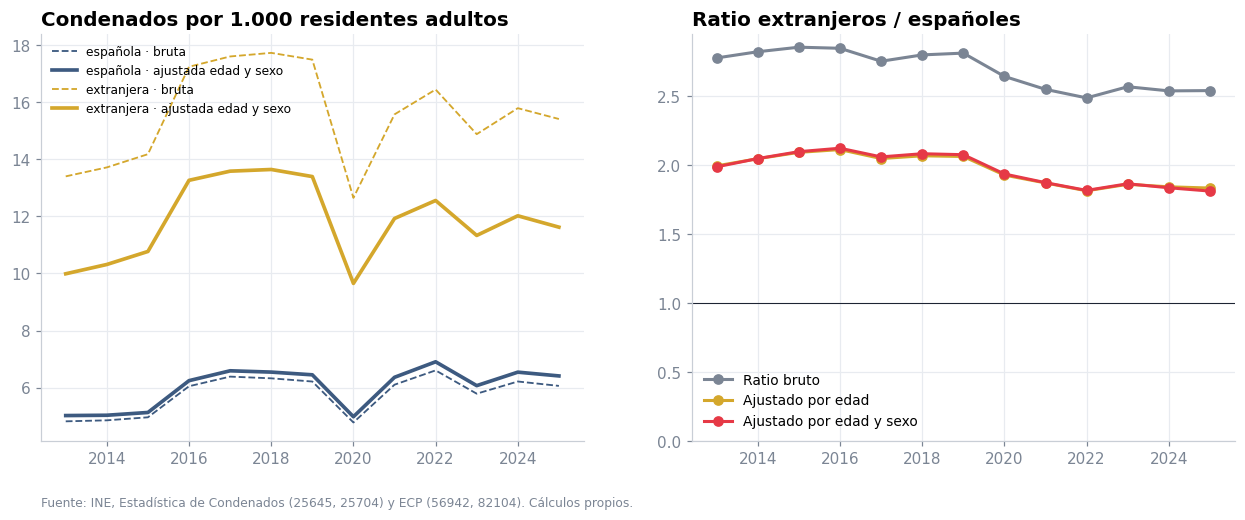

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for nat, col in [("española", C["blue"]), ("extranjera", C["gold"])]:
    d = cr[cr.nacionalidad == nat]
    axes[0].plot(d.anyo, d.tasa_bruta, color=col, lw=1.2, ls="--", label=f"{nat} · bruta")
    axes[0].plot(d.anyo, d.tasa_edad_sexo, color=col, lw=2.4, label=f"{nat} · ajustada edad y sexo")
axes[0].set_title("Condenados por 1.000 residentes adultos"); axes[0].legend(fontsize=8)
axes[1].plot(ratios.index, ratios.ratio_bruta, marker="o", color=C["muted"], label="Ratio bruto")
axes[1].plot(ratios.index, ratios.ratio_edad, marker="o", color=C["gold"], label="Ajustado por edad")
axes[1].plot(ratios.index, ratios.ratio_edad_sexo, marker="o", color=C["red"], label="Ajustado por edad y sexo")
axes[1].axhline(1, color=C["ink"], lw=0.7); axes[1].set_ylim(0, None)
axes[1].set_title("Ratio extranjeros / españoles"); axes[1].legend()
P.source(axes[0], "INE, Estadística de Condenados (25645, 25704) y ECP (56942, 82104). Cálculos propios."); P.save(fig, "22_condenas"); plt.show()

**Lectura.**

- En términos **brutos**, la tasa de condenados extranjeros es unas **2,5 veces** la de los españoles.
- Al **ajustar por edad**, el ratio baja a **~1,8**: el exceso pasa de +154% a +84%, es decir, **casi la mitad del exceso** se explica solo porque la población extranjera es más joven. El ajuste adicional por sexo apenas cambia el resultado.
- La diferencia restante **no se puede atribuir a la nacionalidad**: incluye el efecto de los no residentes en el numerador, los sesgos de detección y enjuiciamiento y factores socioeconómicos no observados.
- **Tendencia:** el ratio ajustado **desciende** desde ~2,1 (2015-2016) a ~1,8 (2025), mientras que el peso de los extranjeros en la población adulta crece. Es decir, **más inmigración no se ha traducido en una mayor sobrerrepresentación relativa** en las condenas.

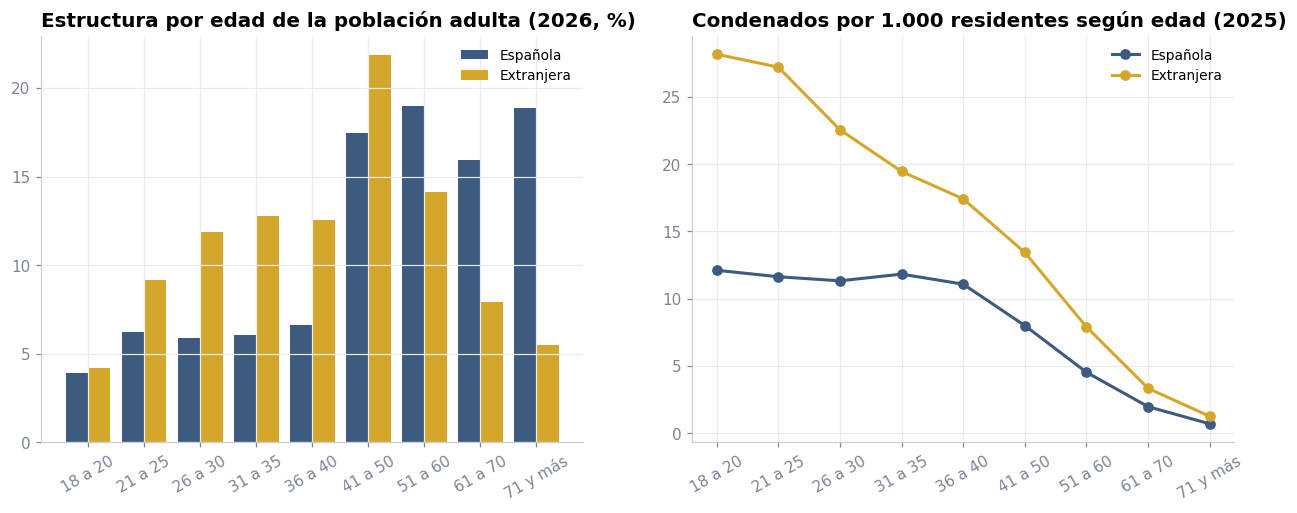

In [30]:
ast = A.age_structure()
rates_age = cr[cr.anyo == cr.anyo.max()].set_index("nacionalidad")[[f"tasa_{b}" for b in A.CONDENA_BANDS]].T
rates_age.index = A.CONDENA_BANDS
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
x = np.arange(len(A.CONDENA_BANDS)); w = 0.4
axes[0].bar(x - w/2, ast["española"], w, label="Española", color=C["blue"]); axes[0].bar(x + w/2, ast["extranjera"], w, label="Extranjera", color=C["gold"])
axes[0].set_xticks(x, [b.replace("De ", "").replace(" años", "") for b in A.CONDENA_BANDS], rotation=30)
axes[0].set_title(f"Estructura por edad de la población adulta ({ast.attrs['year']}, %)"); axes[0].legend()
axes[1].plot(x, rates_age["española"], marker="o", color=C["blue"], label="Española")
axes[1].plot(x, rates_age["extranjera"], marker="o", color=C["gold"], label="Extranjera")
axes[1].set_xticks(x, [b.replace("De ", "").replace(" años", "") for b in A.CONDENA_BANDS], rotation=30)
axes[1].set_title(f"Condenados por 1.000 residentes según edad ({cr.anyo.max()})"); axes[1].legend()
P.save(fig, "23_condenas_edad"); plt.show()

**Lectura.** La izquierda explica el ajuste: **casi la mitad (~46%) de los adultos extranjeros tiene entre 21 y 40 años, frente a una cuarta parte (~25%) de los españoles**, de los que más de la mitad supera los 50. Y en ambas nacionalidades la tasa de condena es **máxima entre los 18 y los 25 años** y cae con fuerza a partir de los 40. Comparar tasas brutas equivale, en parte, a comparar jóvenes con mayores. Incluso dentro de cada tramo de edad la tasa de los extranjeros es mayor (≈2,3× en los más jóvenes, ≈1,7× a partir de los 40), lo que es coherente con el ratio ajustado.

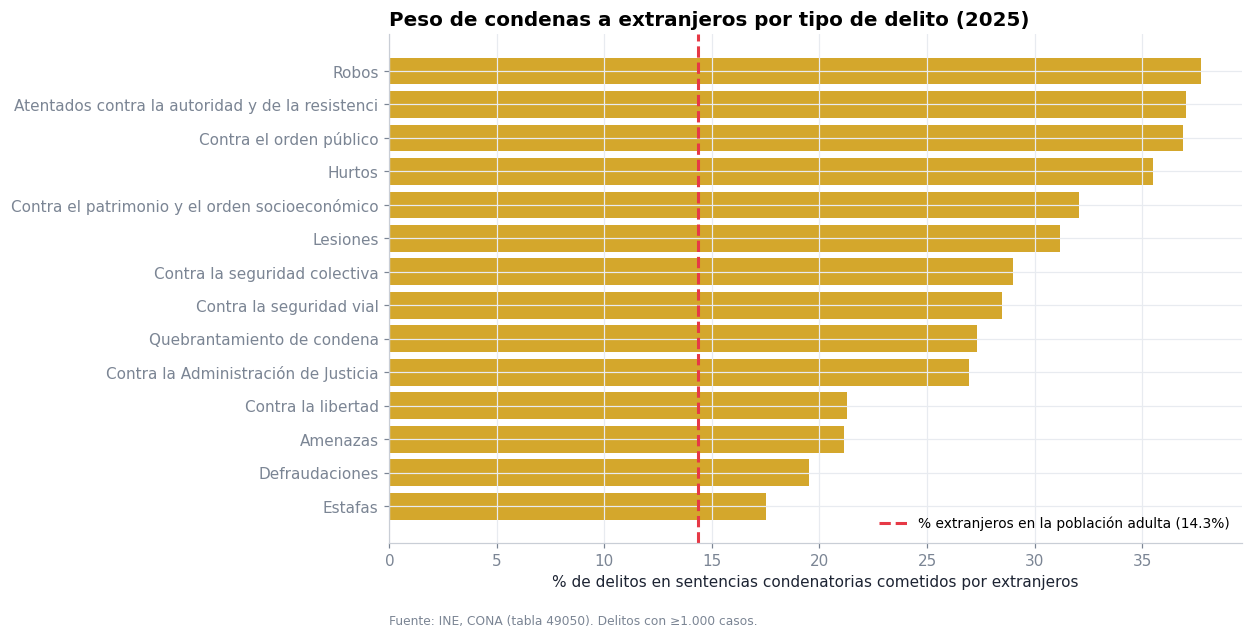

,total,española,extranjera,pct_extranjera
dim,,,,
Contra el patrimonio y el orden socioeconómico,"147,026.00","99,882.00","47,144.00",32.07
Contra la seguridad colectiva,"117,147.00","83,162.00","33,985.00",29.01
Contra la seguridad vial,"103,127.00","73,730.00","29,397.00",28.51
Lesiones,"79,565.00","54,765.00","24,800.00",31.17
Hurtos,"75,515.00","48,690.00","26,825.00",35.52
Contra la libertad,"33,115.00","26,070.00","7,045.00",21.27
Defraudaciones,"26,453.00","21,290.00","5,163.00",19.52
Contra la Administración de Justicia,"26,436.00","19,305.00","7,131.00",26.97
Amenazas,"25,807.00","20,351.00","5,456.00",21.14


In [31]:
ct = A.crimes_by_type(); share_ext = A.foreign_adult_share()
ref = share_ext.loc[ct.attrs["year"]]
fig, ax = plt.subplots(figsize=(10, 6))
c = ct.sort_values("pct_extranjera")
ax.barh([i[:48] for i in c.index], c.pct_extranjera, color=C["gold"])
ax.axvline(ref, color=C["red"], ls="--", label=f"% extranjeros en la población adulta ({ref:.1f}%)")
ax.set_xlabel("% de delitos en sentencias condenatorias cometidos por extranjeros")
ax.set_title(f"Peso de condenas a extranjeros por tipo de delito ({ct.attrs['year']})"); ax.legend(loc="lower right")
P.source(ax, "INE, CONA (tabla 49050). Delitos con ≥1.000 casos."); P.save(fig, "24_delitos_tipo"); plt.show()
display(ct[["total", "española", "extranjera", "pct_extranjera"]])

**Lectura.** La sobrerrepresentación **varía mucho según el tipo de delito**: es mayor en **robos, hurtos y delitos contra el orden público o la autoridad** (más ligados a la marginalidad, a la delincuencia itinerante y a la presencia policial en la calle) y menor en **estafas, defraudaciones o amenazas**. Ninguna de estas cifras está ajustada por edad: comparadas con el 14% de población adulta extranjera exageran la diferencia, por las razones explicadas arriba.

> **Conclusión del bloque:** los datos muestran una **sobrerrepresentación real pero mucho menor** de lo que sugieren las cifras brutas, y **decreciente** en la última década. Cualquier uso de estas cifras en el debate público debería, como mínimo, ajustar por edad y explicitar que son condenas y no delitos.

<a id="13"></a>
## 13 · Territorio: las 17 comunidades

In [32]:
ct = A.ccaa_table().drop(index=["Ceuta", "Melilla"], errors="ignore")
display(ct.sort_values("paro").style.format(precision=1, na_rep="—")
        .background_gradient(cmap="RdYlGn_r", subset=["paro", "arope", "ipv", "brecha"])
        .background_gradient(cmap="RdYlGn", subset=["empleo", "salario"]))

,paro,paro_delta,empleo,arope,ipv,ipc,salario,alquiler,brecha
dim,,,,,,,,,
Baleares,4.6,-6.5,75.5,15.2,13.7,5.1,29075.1,4.0,7.6
País Vasco,7.2,0.8,74.7,14.7,10.0,5.0,35170.3,—,14.0
Cantabria,7.6,0.2,73.8,19.2,13.5,5.4,27097.2,3.3,20.6
Castilla y León,7.8,-1.8,70.2,24.1,14.8,5.4,26177.3,3.0,17.4
Madrid,8.2,-1.5,77.9,19.4,12.9,5.3,34410.0,3.4,17.5
Cataluña,8.3,-0.9,76.4,21.3,10.1,4.5,31730.0,3.1,15.7
La Rioja,8.6,-1.1,77.1,22.8,14.4,4.6,27855.4,3.1,13.9
Navarra,9.2,-0.1,75.7,16.5,9.5,5.3,32605.3,—,20.4
Galicia,9.2,-0.0,72.5,22.1,12.9,5.5,26547.3,3.4,14.3


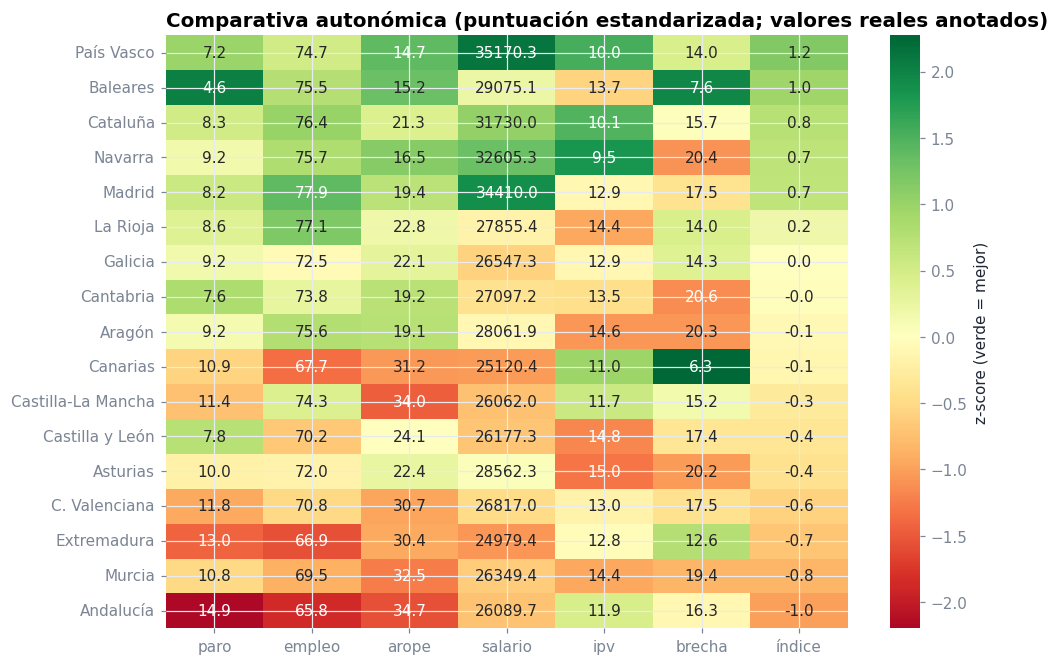

In [33]:
z = ct.drop(index="España")[["paro", "empleo", "arope", "salario", "ipv", "brecha"]]
zs = (z - z.mean()) / z.std()
for c in ["paro", "arope", "ipv", "brecha"]: zs[c] = -zs[c]
zs["índice"] = zs.mean(axis=1)
zs = zs.sort_values("índice", ascending=False)
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(zs, cmap="RdYlGn", center=0, annot=z.loc[zs.index].join(zs[["índice"]]).round(1), fmt="", ax=ax, cbar_kws={"label": "z-score (verde = mejor)"})
ax.set_title("Comparativa autonómica (puntuación estandarizada; valores reales anotados)"); ax.set_ylabel("")
P.save(fig, "25_ccaa_heatmap"); plt.show()

**Lectura.** Aparece un **eje norte-sur muy nítido**. País Vasco, Navarra, Madrid y Cataluña combinan poco paro, alta tasa de empleo, salarios altos y poca pobreza. Andalucía, Extremadura, Canarias y Murcia presentan el patrón opuesto. Baleares es un caso singular: el paro más bajo de España, pero salarios medios y vivienda muy cara.

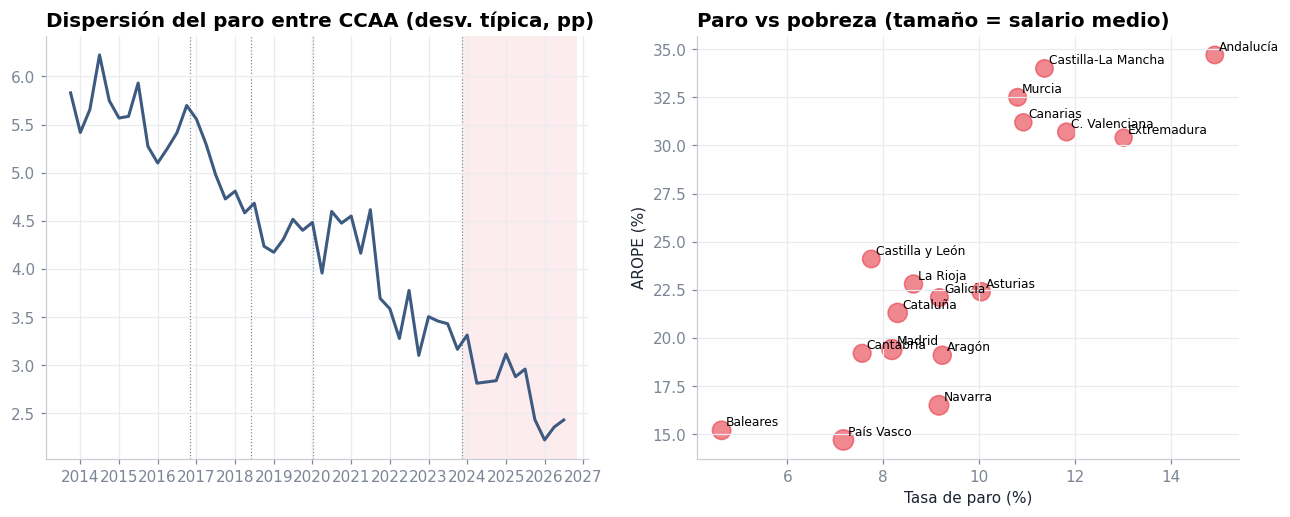

Correlación paro-AROPE entre CCAA: 0.85


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sg = A.sigma_convergence(); axes[0].plot(sg.index, sg.values, color=C["blue"]); P.shade_legislatures(axes[0], labels=False)
axes[0].set_title("Dispersión del paro entre CCAA (desv. típica, pp)")
d = ct.drop(index="España")
axes[1].scatter(d.paro, d.arope, s=d.salario / 200, color=C["red"], alpha=0.6)
for name, r in d.iterrows(): axes[1].annotate(name, (r.paro, r.arope), fontsize=8, xytext=(3, 3), textcoords="offset points")
axes[1].set_xlabel("Tasa de paro (%)"); axes[1].set_ylabel("AROPE (%)"); axes[1].set_title("Paro vs pobreza (tamaño = salario medio)")
P.save(fig, "26_convergencia"); plt.show()
print(f"Correlación paro-AROPE entre CCAA: {d.paro.corr(d.arope):.2f}")

**Lectura.** Las comunidades **convergen** en paro: la dispersión se ha reducido a menos de la mitad desde 2013. La relación paro–pobreza entre comunidades es **muy fuerte**: el empleo es el principal canal de reducción de la pobreza, de ahí la importancia de que la mejora laboral llegue a las regiones del sur.

<a id="14"></a>
## 14 · Relaciones macro y comparativa entre legislaturas

### 14.1 Correlaciones entre indicadores trimestrales

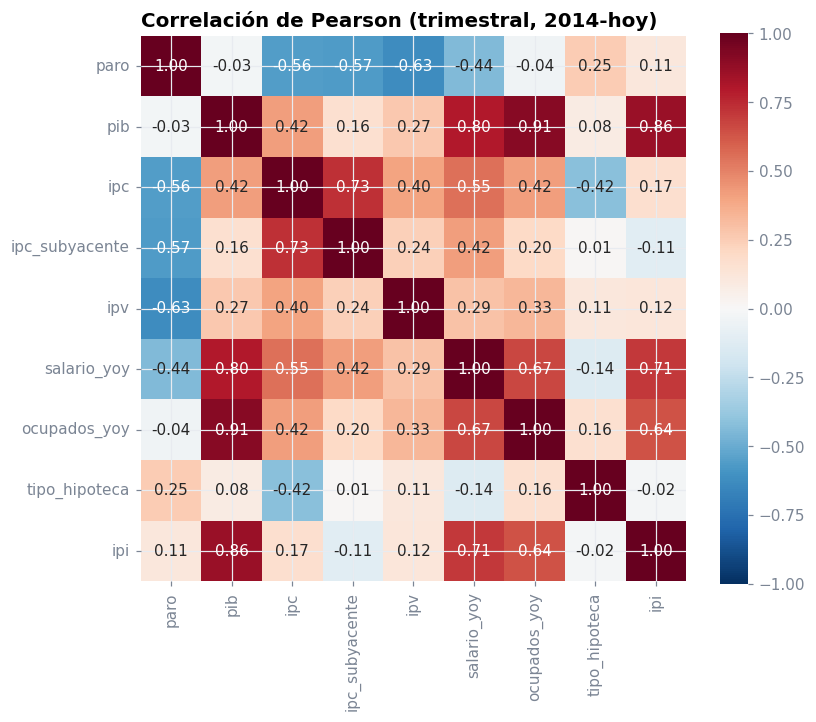

In [35]:
cm = A.correlation_matrix()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, fmt=".2f", square=True)
ax.set_title("Correlación de Pearson (trimestral, 2014-hoy)"); P.save(fig, "27_correlaciones"); plt.show()

**Lectura.** Las correlaciones más fuertes son las esperables: **PIB–empleo (0,9)**, PIB–industria y PIB–salarios. El paro se correlaciona **negativamente con la inflación** (relación de Phillips) y con el precio de la vivienda: en las fases de poco paro suben precios y vivienda. Atención: son correlaciones en series con tendencia y con el COVID, por lo que **no implican causalidad**.

### 14.2 Curva de Phillips e índice de miseria

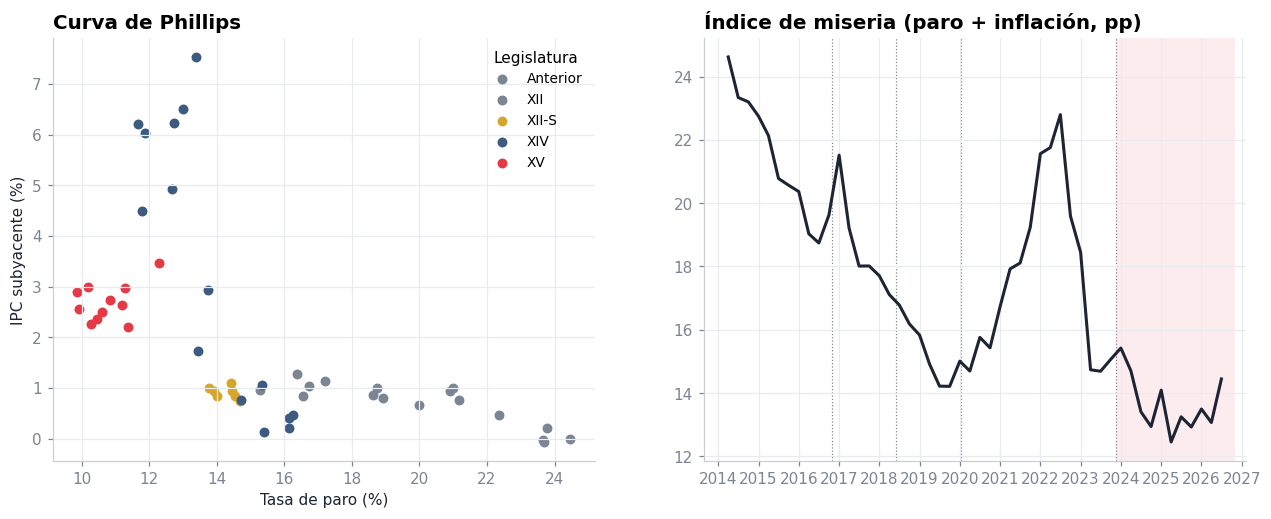

Índice de miseria: inicio XV 15.1 → último 14.4


In [36]:
p = A.quarterly_panel().dropna(subset=["paro", "ipc_subyacente"])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for leg, g in p.groupby("legislatura"):
    axes[0].scatter(g.paro, g.ipc_subyacente, label=leg, s=30, color={"XV": C["red"], "XIV": C["blue"], "XII-S": C["gold"]}.get(leg, C["muted"]))
axes[0].set_xlabel("Tasa de paro (%)"); axes[0].set_ylabel("IPC subyacente (%)"); axes[0].set_title("Curva de Phillips"); axes[0].legend(title="Legislatura")
mi = p["indice_miseria"].dropna(); axes[1].plot(mi.index, mi.values, color=C["ink"]); P.shade_legislatures(axes[1], labels=False)
axes[1].set_title("Índice de miseria (paro + inflación, pp)")
P.save(fig, "28_phillips"); plt.show()
print(f"Índice de miseria: inicio XV {A.value_at(mi, A.XV)[1]:.1f} → último {mi.iloc[-1]:.1f}")

**Lectura.** La nube de la XV se sitúa a la **izquierda** (menos paro) con inflación subyacente moderada: es la legislatura con el **índice de miseria** (paro + inflación, popularizado por Okun) **medio más bajo** de la muestra (~13,7 frente a 17,8 en la XIV y 18,6 en la XII). Tocó mínimo en 2025 (~12,5) y el repunte energético de 2026 lo devuelve a ~14,4.

### 14.3 XIV vs XV: los mismos meses desde la investidura

Alineamos cada indicador por **meses transcurridos desde la investidura** para comparar trayectorias equivalentes. **Cautela:** la XIV empieza dos meses antes del COVID, así que su trayectoria inicial está dominada por la pandemia.

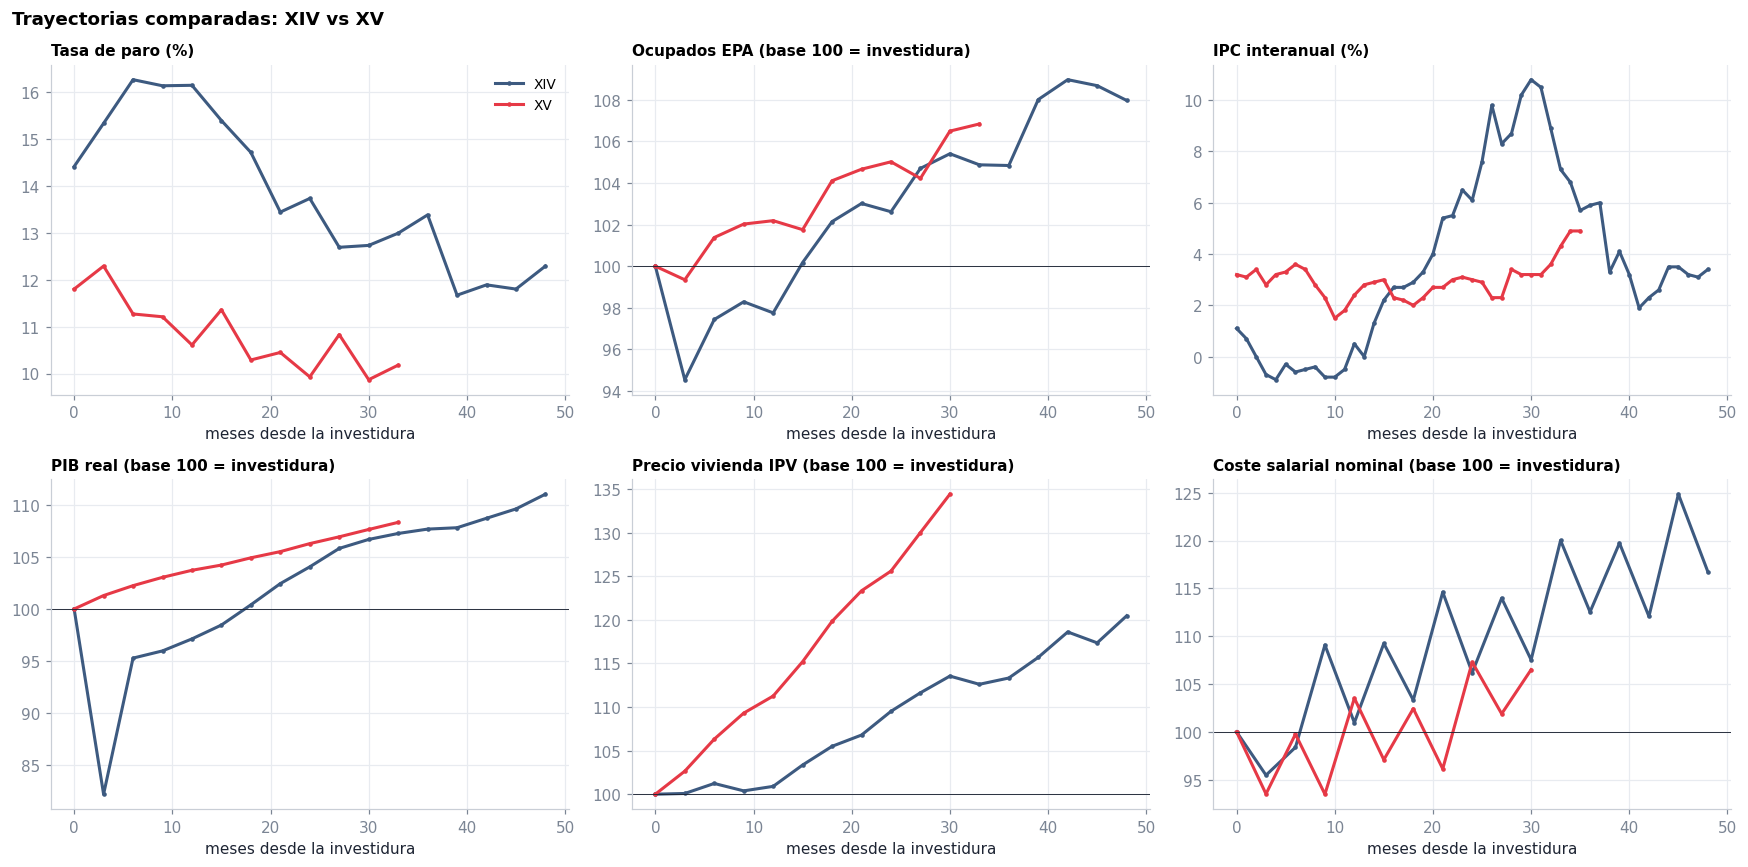

In [37]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (key, (mode, title)) in zip(axes.flat, A.EVENT_KEYS.items()):
    ev = A.event_study(key, mode)
    for leg, col in [("XIV", C["blue"]), ("XV", C["red"])]:
        e = ev[ev.legislatura == leg]; ax.plot(e.mes, e.valor, label=leg, color=col, marker="o", ms=2)
    ax.set_title(title, fontsize=10); ax.set_xlabel("meses desde la investidura")
    if mode == "index": ax.axhline(100, color=C["ink"], lw=0.6)
axes[0, 0].legend(); fig.suptitle("Trayectorias comparadas: XIV vs XV", fontweight="bold", x=0.01, ha="left")
fig.tight_layout(); P.save(fig, "29_event_study"); plt.show()

**Lectura.** Con los mismos meses transcurridos, la XV muestra **menos paro**, más empleo y un PIB que crece sin interrupciones. La XIV tuvo una caída brusca (COVID) y una recuperación muy rápida. En **vivienda**, la XV va claramente **por encima**: los precios suben más rápido que en la legislatura anterior.

<a id="15"></a>
## 15 · Conclusiones y limitaciones

### Hallazgos automáticos
Generados por `analytics.insights()` a partir de los datos más recientes (se actualizan al regenerar el dataset):

In [38]:
for i in A.insights():
    icon = {"good": "🟢", "bad": "🔴"}.get(i["tone"], "⚪")
    display(Markdown(f"{icon} **{i['title']}** — {i['body']}"))

🟢 **El paro, cerca de sus mínimos desde 2013** — La tasa de paro pasa de 11,80% (T4 2023) a 10,18% (T3 2026): -1,62 pp en la legislatura.

🟢 **Ocupación en máximos de la serie** — La EPA suma 1.463 mil ocupados desde el inicio de la XV, hasta 22,85 millones.

🟢 **Paro juvenil: 2,3 veces la media** — El paro de menores de 25 años está en 23,3% (-5,2 pp desde el inicio de legislatura).

🔴 **La inflación repunta** — El IPC interanual pasa de 3,2% a 4,9% (oct 2026); la subyacente está en 3,1% y la energía en 20,9%. La energía tira del índice general.

🟢 **Poder adquisitivo de los salarios** — Desde el inicio de la legislatura el coste salarial nominal crece un 9,6% y los precios un 7,7%: el salario real varía un 1,8%.

🔴 **La vivienda se aleja de los salarios** — Desde 2015 el precio de la vivienda (IPV) ha subido un 100% y los salarios un 28%. El índice de esfuerzo está en 156 (2015 = 100).

🟢 **El PIB crece un 2,7% interanual** — Crecimiento real del PIB en T3 2026, frente al 2,2% de T4 2023.

🟢 **Pobreza y exclusión (AROPE)** — La tasa AROPE se sitúa en 25,7% (2025), -0,8 pp respecto a 2023: afecta a aproximadamente 1 de cada 4 residentes.

🟢 **La brecha salarial de género se estrecha** — Por hora trabajada, las mujeres cobran un 8,0% menos (2024), frente al 15,9% de 2009. En ganancia anual la brecha es mayor (16,1%) por la mayor parcialidad femenina.

⚪ **Condenas por nacionalidad: la demografía explica parte de la diferencia** — En 2025 hay 15,4 condenados por mil adultos extranjeros y 6,1 por mil españoles (ratio 2,54). Al ajustar por edad y sexo el ratio baja a 1,81: la diferencia se reduce pero no desaparece. Son condenas, no delitos cometidos, e incluyen a no residentes.

🟢 **Convergencia territorial del paro** — La desviación típica del paro entre CCAA cae de 5,83 pp (T4 2013) a 2,43 pp: las regiones se parecen cada vez más.

### Balance

| ✅ Mejoras claras | ⚠️ Mixto | ❌ Deterioro / pendiente |
|---|---|---|
| Paro en torno al 10% (mínimos desde 2008) y empleo récord | Salario real: ganancia pequeña, amenazada por la inflación energética | **Vivienda**: precios en dobles dígitos y esfuerzo +50% vs 2015 |
| Temporalidad en mínimos (efecto reforma 2022) | Pobreza y exclusión bajan, pero 1 de cada 4 sigue en riesgo | **Productividad** estancada y CLU al alza |
| Crecimiento del PIB > 2% | Paro juvenil mejora, pero sigue >2× la media | Repunte de la **inflación general** en 2026 |
| Brecha salarial por hora a la mitad en 15 años | Convergencia territorial con fuerte eje norte-sur | Natalidad en mínimos |
| Compresión salarial (SMI) y menor desigualdad | Sobrerrepresentación de extranjeros en condenas: real pero decreciente y mucho menor ajustada por edad | |

### Limitaciones
- **Correlación no es causalidad**: no se estima el efecto de políticas concretas frente a factores externos (BCE, energía, turismo, fondos NextGenEU).
- **Desfases**: ECV, EAES, IPVA y condenados cubren solo el primer año (o dos) de la legislatura.
- **Revisiones**: PIB y EPA se revisan; los resultados pueden cambiar al regenerar el dataset.
- **Una sola fuente**: el INE no cubre deuda y déficit (Banco de España/IGAE), afiliación (Seguridad Social), sanidad o educación (ministerios), ni criminalidad registrada (Ministerio del Interior).

### Próximos pasos
- Incorporar **Eurostat** para comparar con la UE.
- Añadir **Balance de Criminalidad** (Interior) para contrastar con las condenas.
- Modelo de **descomposición Oaxaca-Blinder** de la brecha salarial con microdatos de la EAES.